# What Makes a Story Stick?

### Critic and audience reception of films and books

This notebook asks what separates well-received stories from poorly received ones, using reviews scraped from **Goodreads** (books) and **Rotten Tomatoes** (films, with separate critic and audience voices).

### Research questions

1. **Review language and reception.** Do the words reviewers use predict the rating they give, on data the model has never seen? Do critics, audiences and readers signal approval with different words?
2. **Genre and the critic–audience split.** Which genres are associated with higher or lower ratings, and which genres do critics and audiences disagree on?

Question 2 is a first pass. Two sharper questions replace it, each in its own notebook: where critics and audiences disagree (`gap-analysis.ipynb`) and what makes a book divisive (`divisive-books.ipynb`).

### Data (after `data-cleaning.ipynb`)

| Dataset | Rows | Key fields |
|---|---|---|
| Goodreads books | 4,997 books | average rating, genres, description |
| Goodreads reviews | 135,361 reviews (127,040 English) | rating (1–5), review text |
| Rotten Tomatoes movies | 3,001 films (2,454 with both a critic and audience score) | Tomatometer, audience score, genres, release year, runtime |
| RT critic reviews | 25,136 reviews | rating (parsed to 0–5), fresh/rotten, review text |
| RT audience reviews | 15,264 reviews | score (0.5–5), review text |

### How this differs from the class version

- **Every score is on held-out data.** Reviews are split by title, so the model is tested on books and films it never saw. The class version reported R² on its own training data.
- **Baselines.** Each model is compared with predicting the average and with the title's published average rating.
- **Regularized models.** Ridge regression, with the penalty chosen by grouped cross-validation, replaces unregularized linear regression.
- **Many model families compared.** OLS, Ridge, Lasso, decision trees, random forests and gradient boosting for the rating, and logistic regression (L2 and L1), Naive Bayes and the same tree models for positive vs. negative, all on the same held-out titles.
- **Reviewer leakage checked.** Every model is also scored on held-out reviews from reviewers it never saw.
- **Uncertainty.** Word and genre coefficients get 95% bootstrap intervals, and only those whose interval excludes zero are interpreted.
- **Cleaner inputs.** Language comes from a real detector (Lingua). Genres need at least 30 titles. Films with a missing score are dropped instead of filled with the median.
- **Letterboxd is gone.** Its top-500 and bottom-500 lists were chosen by rating, which inflates any rating model.
- **Wording.** Coefficients are described as *associations*, not effects.

## Setup

In [1]:
import ast
import os
import re
import time
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.colors import LinearSegmentedColormap
from scipy.sparse import csr_matrix, hstack
from sklearn.decomposition import TruncatedSVD
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.ensemble import (HistGradientBoostingClassifier, HistGradientBoostingRegressor,
                              RandomForestClassifier, RandomForestRegressor)
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import Lasso, LinearRegression, LogisticRegression, Ridge
from sklearn.metrics import accuracy_score, f1_score, mean_absolute_error, r2_score, roc_auc_score
from sklearn.model_selection import (GridSearchCV, GroupKFold, GroupShuffleSplit, KFold, RepeatedKFold,
                                     RepeatedStratifiedKFold, StratifiedKFold, cross_val_score, cross_validate)
from sklearn.naive_bayes import MultinomialNB
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor, plot_tree

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 220)

CLEAN_DIR = 'data/cleaned'
FIG_DIR = 'figures'                    # charts used in the README
os.makedirs(FIG_DIR, exist_ok=True)
SEED = 42
TEXT_ALPHAS = [0.3, 1, 3, 10, 30]      # Ridge penalties tried for the text models
GENRE_ALPHAS = [0.1, 1, 10, 30, 100]   # and for the genre models
N_BOOT = 200                           # bootstrap resamples for word coefficients
MIN_TITLES = 30                        # a genre needs this many titles to be modeled

# Chart palette (reference palette from the dataviz guide)
SURFACE, INK, INK2, GRID = '#fcfcfb', '#0b0b0b', '#52514e', '#e6e5e1'
POS, NEG, MID = '#2a78d6', '#e34948', '#f0efec'      # diverging: blue = higher, red = lower
SERIES = ['#2a78d6', '#eb6834', '#1baf7a']           # categorical slots 1-3
OLD = '#b8b7b2'                                      # muted gray for the class version's numbers
DIVERGING = LinearSegmentedColormap.from_list('diverging', [NEG, MID, POS])

plt.rcParams.update({
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE,
    'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'axes.titlecolor': INK,
    'axes.titlesize': 13, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.axisbelow': True,
    'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.8,
    'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'font.size': 10, 'legend.frameon': False, 'figure.dpi': 110,
})

In [2]:
books = pd.read_csv(f'{CLEAN_DIR}/cleaned_goodreads_books.csv')
movies = pd.read_csv(f'{CLEAN_DIR}/cleaned_rotten_tomatoes_movies.csv')
reviews = {
    'Goodreads':   pd.read_csv(f'{CLEAN_DIR}/cleaned_goodreads_reviews.csv'),
    'RT audience': pd.read_csv(f'{CLEAN_DIR}/cleaned_rotten_tomatoes_audience_reviews.csv'),
    'RT critics':  pd.read_csv(f'{CLEAN_DIR}/cleaned_rotten_tomatoes_critic_reviews.csv'),
}
TITLE_KEY = {'Goodreads': 'book_id', 'RT audience': 'movie_url', 'RT critics': 'movie_url'}
REVIEWER_KEY = {'Goodreads': 'reviewer_id', 'RT audience': 'reviewer_id', 'RT critics': 'critic_name'}

# CSV flattens lists to strings; turn genres back into lists
for df in (books, movies):
    df['genres_list'] = df['genres_list'].map(ast.literal_eval)

for label, df in reviews.items():
    print(f"{label:12s} {len(df):>8,} reviews  {df[TITLE_KEY[label]].nunique():>6,} titles")

Goodreads     135,361 reviews   4,951 titles
RT audience    15,264 reviews   2,874 titles
RT critics     25,136 reviews   2,894 titles


# Research Question 1: Does review language predict ratings?

**Do the words reviewers use predict the rating they give, on data the model has never seen? Do critics, audiences and readers signal approval with different words?**

### Method
1. Keep English reviews that have a rating.
2. Hold out 20% of **titles** as a test set. All reviews of a held-out book or film are unseen, so a model can't score well by recognizing a title's name.
3. Turn text into TF-IDF features (5,000 single words and two-word phrases), fit on the training titles only.
4. Pick the Ridge penalty with 5-fold cross-validation grouped by title, inside the training set.
5. Score once on the held-out titles, next to two baselines and the class version's model.
6. Bootstrap the training titles 200 times to get a 95% interval for each word's coefficient.
7. Check reviewer leakage (1.3), then compare other model families on the same split (1.4–1.5).

### 1.1 English filter: old heuristic vs. Lingua

The class version kept a review if at least 25% of its words were on a list of common English words. The cleaning notebook now labels each review with Lingua. The table compares the two.

In [3]:
COMMON_EN = set('''the be to of and a in that have i it for not on with he as you do at this but his by from they
we say her she or an will my one all would there their what so up out if about who get which go me when make can
like time no just him know take people into year your good some could them see other than then now look only come
its over think also back after use two how our work first well way even new want because any these give day most us
great movie film book story was were been had did are is has much very really bad best worst love loved hate hated
watch watched read never always every nothing something everything enough through before again more still too own
off'''.split())

def old_is_english(text, threshold=0.25):
    # The class version's heuristic, kept only for this comparison
    words = re.findall(r'[a-z]+', str(text).lower())
    if len(str(text).strip()) < 20 or len(words) < 5:
        return False
    return sum(w in COMMON_EN for w in words) / len(words) >= threshold

rows, disagreements = [], {}
for label, df in reviews.items():
    old = df['review_text'].map(old_is_english)
    new = df['language'].eq('en')
    rows.append({'platform': label, 'reviews': len(df),
                 'English (old heuristic)': old.sum(), 'English (Lingua)': new.sum(),
                 'agree': f"{(old == new).mean():.1%}",
                 'only old says English': (old & ~new).sum(), 'only Lingua says English': (~old & new).sum()})
    disagreements[label] = df[old != new].assign(old=old[old != new], lingua=df['language'][old != new])
display(pd.DataFrame(rows).set_index('platform'))

print('Goodreads examples where the two disagree:')
display(disagreements['Goodreads'][['lingua', 'old', 'review_text']]
        .assign(review_text=lambda d: d['review_text'].str.slice(0, 160))
        .sample(8, random_state=SEED))

,reviews,English (old heuristic),English (Lingua),agree,only old says English,only Lingua says English
platform,,,,,,
Goodreads,135361,125671,125769,99.2%,497,595
RT audience,15264,14524,14752,98.0%,37,265
RT critics,25136,24490,25103,97.4%,18,631


Goodreads examples where the two disagree:


,lingua,old,review_text
60500,fa,True,: The reasons I don't like this book: - 244: Surah Al-Baqarah [2:244]: Kill in the name of Allah and for his cause and know that Allah hears and knows. - 5: Sur
14814,ar,True,""" "" , , 1980 VS 2008 Hypatia 1853 1853 , 2008 - - , , - ... , , "" "" .. , , .. "" "".. ****************************** ... .. - !!!- : "" Song of the Songs : . ( ) ."
8811,es,True,"He ido desmenuzando y degustando cada uno de estos casos. Los casos me parecen interesantes, pero son casos menores dentro de la vida de Sherlock Holmes. Alguno"
103479,en,False,"Burn in Hell, Colonel Nicholson!"
89086,fa,True,. . . . . . . . . . . . Forgiveness is giving up the hope that the past could have been any different. Maede's Books / /
99012,en,False,"What an incredible, complicated, witty, damaged, talented, creative, self-destructive and intelligent woman."
33976,ar,True,", , , .. .. ~~~~~~ .. ... .. 3 ' ' '' 3 ... ... ... - - .. .. .. Memento (2000) 50 First Dates (2004) , , - - ---------------------- ~~~~~~~~~~~ .. , . ..."" :))"
54903,bg,True,"The Bulgarian review is first, the English translation follows it below "" , , , ."" ... , . . , , - . , , . 1945 . ( "" "") 27 , , , , , , . , ( ) . - , "" "". , - ("


In [4]:
q1 = {label: df[df['language'].eq('en') & df['rating_normalized'].notna()].reset_index(drop=True)
      for label, df in reviews.items()}
for label, df in q1.items():
    print(f"{label:12s} {len(df):>8,} English reviews with a rating, {df[TITLE_KEY[label]].nunique():,} titles")

Goodreads     122,331 English reviews with a rating, 4,938 titles
RT audience    14,752 English reviews with a rating, 2,870 titles
RT critics     15,595 English reviews with a rating, 2,848 titles


### 1.2 Held-out evaluation

Models compared on the same held-out titles:

| Model | What it uses |
|---|---|
| **Class version (OLS), scored on training data** | the number the class report used |
| **Class version (OLS), held-out titles** | same model, honest test |
| **Baseline: training mean** | predicts the average rating for every review |
| **Baseline: title's published average** | the book's or film's overall average on the platform, rescaled to 0–1. It partly includes the review being predicted, so treat it as a reference point rather than a fair competitor. |
| **Ridge on review text** | TF-IDF + Ridge, penalty tuned by grouped CV |
| **Ridge on text + title average** | does the text add anything beyond knowing which title it is? |

Ratings are on the 0–1 scale from the cleaning notebook. MAE of 0.10 is about 0.4 stars on Goodreads.

In [5]:
TITLE_AVERAGE = {
    'Goodreads':   ((books.set_index('book_id')['avg_rating'] - 1) / 4),
    'RT audience': ((movies.set_index('movie_url')['audience_avg_rating'] - 0.5) / 4.5).clip(0, 1),
    'RT critics':  (movies.set_index('movie_url')['critic_avg_rating'] / 10).clip(0, 1),
}

def make_vectorizer():
    return TfidfVectorizer(max_features=5000, stop_words='english', min_df=5, max_df=0.95,
                           ngram_range=(1, 2), token_pattern=r'(?u)\b[a-zA-Z]{3,}\b', dtype=np.float32)

def evaluate_platform(label, df):
    start = time.time()
    y = df['rating_normalized'].to_numpy()
    groups = df[TITLE_KEY[label]].to_numpy()
    train, test = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(df, y, groups))
    y_train, y_test = y[train], y[test]

    vec = make_vectorizer()
    X_train = vec.fit_transform(df['review_text'].iloc[train])
    X_test = vec.transform(df['review_text'].iloc[test])

    # Choose the Ridge penalty with 5-fold CV grouped by title, on training titles only
    cv = {a: [] for a in TEXT_ALPHAS}
    for tr, va in GroupKFold(n_splits=5).split(X_train, y_train, groups[train]):
        for a in TEXT_ALPHAS:
            fold = Ridge(alpha=a).fit(X_train[tr], y_train[tr])
            cv[a].append(r2_score(y_train[va], fold.predict(X_train[va])))
    alpha = max(TEXT_ALPHAS, key=lambda a: np.mean(cv[a]))

    ridge = Ridge(alpha=alpha).fit(X_train, y_train)
    ridge_pred = np.clip(ridge.predict(X_test), 0, 1)

    ols = LinearRegression().fit(X_train, y_train)          # the class version's model

    title_avg = df[TITLE_KEY[label]].map(TITLE_AVERAGE[label]).fillna(y_train.mean()).to_numpy()
    add_avg = lambda X, idx: hstack([X, csr_matrix(title_avg[idx, None])]).tocsr()
    combo = Ridge(alpha=alpha).fit(add_avg(X_train, train), y_train)

    preds = {
        'Class version (OLS), held-out titles': ols.predict(X_test),
        'Baseline: training mean': np.full(len(test), y_train.mean()),
        "Baseline: title's published average": title_avg[test],
        'Ridge on review text': ridge_pred,
        'Ridge on text + title average': np.clip(combo.predict(add_avg(X_test, test)), 0, 1),
    }
    rows = {'Class version (OLS), scored on training data':
            {'R²': ols.score(X_train, y_train), 'MAE': mean_absolute_error(y_train, ols.predict(X_train))}}
    rows.update({name: {'R²': r2_score(y_test, p), 'MAE': mean_absolute_error(y_test, p)}
                 for name, p in preds.items()})

    cv_table = pd.DataFrame({a: [np.mean(s), np.std(s)] for a, s in cv.items()}, index=['mean R²', 'sd']).T
    print(f"{label}: {len(train):,} train / {len(test):,} test reviews "
          f"({len(np.unique(groups[test])):,} held-out titles). Best alpha {alpha}, "
          f"CV R² {np.mean(cv[alpha]):.3f} ± {np.std(cv[alpha]):.3f}. {time.time() - start:.0f}s")

    # Which held-out reviews come from a reviewer who also appears in training?
    reviewer = df[REVIEWER_KEY[label]]
    seen = set(reviewer.iloc[train].dropna())
    unseen = (reviewer.iloc[test].notna() & ~reviewer.iloc[test].isin(seen)).to_numpy()

    test_frame = df.iloc[test].assign(predicted=ridge_pred, error=ridge_pred - y_test)
    return dict(label=label, alpha=alpha, cv=cv_table, scores=pd.DataFrame(rows).T, vec=vec, ridge=ridge,
                df=df, train_idx=train, test_idx=test, X_train=X_train, X_test=X_test, y_train=y_train, y_test=y_test,
                groups_train=groups[train], unseen=unseen, preds=preds, test=test_frame)

results = {label: evaluate_platform(label, df) for label, df in q1.items()}

Goodreads: 98,007 train / 24,324 test reviews (988 held-out titles). Best alpha 3, CV R² 0.463 ± 0.009. 94s


RT audience: 11,790 train / 2,962 test reviews (574 held-out titles). Best alpha 3, CV R² 0.542 ± 0.011. 3s


RT critics: 12,541 train / 3,054 test reviews (570 held-out titles). Best alpha 3, CV R² 0.277 ± 0.014. 1s


In [6]:
scores = pd.concat({label: r['scores'] for label, r in results.items()}, axis=1)
scores.columns = [f'{platform} {metric}' for platform, metric in scores.columns]
display(scores.style.format('{:.3f}').set_caption('R² and MAE on the 0–1 rating scale (held-out titles unless noted)'))

print('Grouped CV R² on the training titles, by Ridge penalty:')
display(pd.concat({label: r['cv'] for label, r in results.items()}, axis=1).round(3))

,Goodreads R²,Goodreads MAE,RT audience R²,RT audience MAE,RT critics R²,RT critics MAE
"Class version (OLS), scored on training data",0.519,0.164,0.784,0.125,0.644,0.097
"Class version (OLS), held-out titles",0.465,0.172,0.314,0.222,0.051,0.158
Baseline: training mean,-0.000,0.236,-0.000,0.302,-0.000,0.167
Baseline: title's published average,0.058,0.224,0.296,0.230,0.495,0.113
Ridge on review text,0.483,0.167,0.557,0.180,0.291,0.137
Ridge on text + title average,0.499,0.164,0.603,0.167,0.546,0.107


Grouped CV R² on the training titles, by Ridge penalty:


Goodreads        RT audience        RT critics       
       mean R²     sd     mean R²     sd    mean R²     sd
0.3      0.452  0.010       0.465  0.018      0.156  0.038
1.0      0.457  0.010       0.533  0.013      0.259  0.023
3.0      0.463  0.009       0.542  0.011      0.277  0.014
10.0     0.460  0.007       0.487  0.009      0.220  0.008
30.0     0.429  0.005       0.371  0.007      0.132  0.004

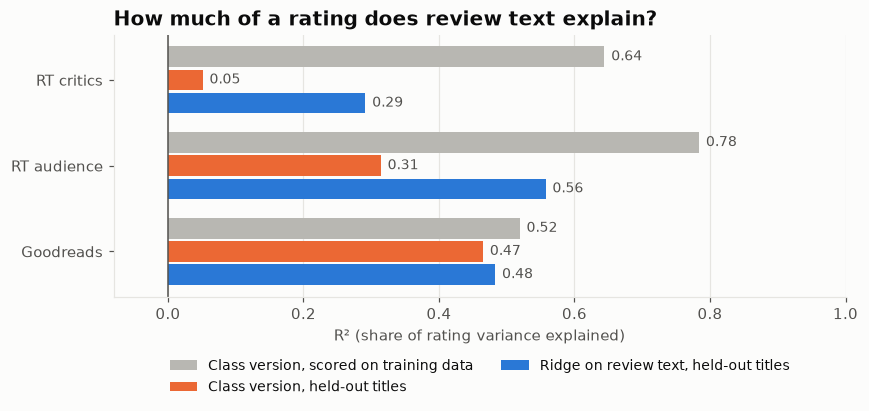

In [7]:
# Chart: the class version's R² vs. honest held-out R²
bars = [('Class version, scored on training data', 'Class version (OLS), scored on training data', OLD),
        ('Class version, held-out titles', 'Class version (OLS), held-out titles', SERIES[1]),
        ('Ridge on review text, held-out titles', 'Ridge on review text', SERIES[0])]
platforms = list(results)
fig, ax = plt.subplots(figsize=(8, 4.2))
height = 0.24
for i, (name, row, color) in enumerate(bars):
    vals = [results[p]['scores'].loc[row, 'R²'] for p in platforms]
    ypos = np.arange(len(platforms)) + (1 - i) * (height + 0.03)
    ax.barh(ypos, vals, height=height, color=color, label=name)
    for yv, v in zip(ypos, vals):
        ax.text(v + (0.01 if v >= 0 else -0.01), yv, f'{v:.2f}', va='center',
                ha='left' if v >= 0 else 'right', color=INK2, fontsize=9)
ax.set_yticks(np.arange(len(platforms)), platforms)
ax.axvline(0, color=INK2, lw=1)
ax.grid(axis='y', visible=False)
ax.set_xlabel('R² (share of rating variance explained)')
ax.set_title('How much of a rating does review text explain?')
ax.legend(loc='lower center', bbox_to_anchor=(0.5, -0.42), ncol=2, fontsize=9)
lo = min(0, min(results[p]['scores']['R²'].min() for p in platforms))
ax.set_xlim(lo - 0.08 if lo < 0 else 0, 1)
plt.tight_layout()
fig.savefig(f'{FIG_DIR}/heldout-r2.png', dpi=160, bbox_inches='tight')
plt.show()

### 1.3 Reviewer leakage check

The split keeps titles apart, but one person can review several titles, and a model can learn a prolific reviewer's habits. Separating titles *and* reviewers at once isn't possible here: linking titles through shared reviewers puts 95–100% of reviews into one connected cluster. Instead, each held-out score is also computed on just the reviews whose reviewer never appears in training. A large drop there would mean the model leans on reviewer identity.

Reviewer IDs: Goodreads user IDs, critic names, and for RT audiences a hash of the display name (first name + initial, so different people can share one). Audience reviews with no name are left out of the unseen group.

In [8]:
rows = []
for label, r in results.items():
    u, y, p = r['unseen'], r['y_test'], r['preds']['Ridge on review text']
    rows.append({'platform': label, 'held-out reviews': len(u), 'from unseen reviewers': int(u.sum()),
                 'share unseen': f'{u.mean():.0%}',
                 'Ridge R², all held-out': r2_score(y, p),
                 'Ridge R², unseen reviewers': r2_score(y[u], p[u]),
                 'Ridge R², repeat reviewers': r2_score(y[~u], p[~u])})
display(pd.DataFrame(rows).set_index('platform').style.format(
    {c: '{:.3f}' for c in ['Ridge R², all held-out', 'Ridge R², unseen reviewers', 'Ridge R², repeat reviewers']}))

,held-out reviews,from unseen reviewers,share unseen,"Ridge R², all held-out","Ridge R², unseen reviewers","Ridge R², repeat reviewers"
platform,,,,,,
Goodreads,24324,8033,33%,0.483,0.525,0.452
RT audience,2962,1369,46%,0.557,0.563,0.551
RT critics,3054,180,6%,0.291,0.249,0.294


**No sign that the model leans on reviewer identity.** On Goodreads and RT audiences, reviews from people the model never saw score as well or *better* (R² 0.53 vs. 0.48 overall on Goodreads; 0.56 vs. 0.56 for audiences). Repeat reviewers are the harder group (R² 0.45 on Goodreads), perhaps because frequent reviewers write longer, more mixed reviews. That's untested here.

**Critics are different.** Only 6% of held-out critic reviews (180) come from a critic absent from training, because almost every critic in this data reviewed several films. Their R² is a little lower (0.25 vs. 0.29), but 180 reviews is too few to separate that from noise. It suggests critics have personal styles a model partly learns, which is worth testing when there's more critic data.

**One reviewer does distort the word lists, though not the scores.** A templated RT audience user puts *hour minutes*, *worldwide* and *company* among the audience's top positive terms (see 1.4 and 1.6). These are artifacts, not real signals, and the next cleaning step should cap reviews per reviewer.

### 1.4 Comparing model families: predicting the rating

The same split, the same TF-IDF features, and the same held-out titles for every model. Each model's settings are chosen on a validation set of 20% of the *training* titles, then the model is refit on all training titles and scored once on the test titles. Predictions are clipped to the 0–1 scale.

| Model | Settings tried | Notes |
|---|---|---|
| Mean baseline | none | predicts the training average |
| Linear regression (OLS) | none | the class version's model |
| Ridge | alpha 0.3–30 | L2 penalty shrinks all coefficients |
| Lasso | alpha 1e-4, 3e-5, 1e-5 | L1 penalty sets most coefficients to exactly zero |
| Decision tree | depth 8, 16, 32 | one tree, at least 20 reviews per leaf |
| Random forest | 100 trees | random feature subsets at each split |
| Gradient boosting | up to 300 rounds | scikit-learn's histogram boosting, run on 300 SVD components of the TF-IDF matrix (it needs dense input) |

In [9]:
def tune_on_inner_split(make, grid, X, y, groups, score):
    # Pick settings on 20% of the training titles, then refit on all training titles
    if len(grid) == 1:
        return make().set_params(**grid[0]).fit(X, y), grid[0]
    tr, va = next(GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=SEED).split(X, y, groups))
    model, best, best_score = make(), None, -np.inf
    for params in grid:                     # one estimator reused, so Lasso warm-starts along the grid
        model.set_params(**params).fit(X[tr], y[tr])
        s = score(model, X[va], y[va])
        if s > best_score:
            best, best_score = params, s
    return make().set_params(**best).fit(X, y), best

for r in results.values():                  # dense, compressed features for gradient boosting
    svd = TruncatedSVD(n_components=300, random_state=SEED).fit(r['X_train'])
    r['S_train'], r['S_test'] = svd.transform(r['X_train']), svd.transform(r['X_test'])

r2_of = lambda m, X, y: r2_score(y, m.predict(X))
REGRESSORS = {   # name: (constructor, settings to try, uses SVD features)
    'Mean baseline':           (DummyRegressor, [{}], False),
    'Linear regression (OLS)': (LinearRegression, [{}], False),
    'Ridge':                   (Ridge, [{'alpha': a} for a in TEXT_ALPHAS], False),
    'Lasso':                   (lambda: Lasso(tol=1e-3, max_iter=6000, warm_start=True),
                                [{'alpha': a} for a in (1e-4, 3e-5, 1e-5)], False),
    'Decision tree':           (lambda: DecisionTreeRegressor(min_samples_leaf=20, random_state=SEED),
                                [{'max_depth': d} for d in (8, 16, 32)], False),
    'Random forest':           (lambda: RandomForestRegressor(n_estimators=100, max_features='sqrt', min_samples_leaf=3,
                                                              n_jobs=-1, random_state=SEED), [{}], False),
    'Gradient boosting':       (lambda: HistGradientBoostingRegressor(max_iter=300, early_stopping=True,
                                                                      random_state=SEED), [{}], True),
}

reg_rows, lasso_models = [], {}
for label, r in results.items():
    u = r['unseen']
    for name, (make, grid, dense) in REGRESSORS.items():
        start = time.time()
        Xtr, Xte = (r['S_train'], r['S_test']) if dense else (r['X_train'], r['X_test'])
        model, best = tune_on_inner_split(make, grid, Xtr, r['y_train'], r['groups_train'], r2_of)
        pred = np.clip(model.predict(Xte), 0, 1)
        if name == 'Lasso':
            lasso_models[label] = model
        terms = int((model.coef_ != 0).sum()) if hasattr(model, 'coef_') else None
        reg_rows.append({'platform': label, 'model': name, 'R²': r2_score(r['y_test'], pred),
                         'MAE': mean_absolute_error(r['y_test'], pred),
                         'R², unseen reviewers': r2_score(r['y_test'][u], pred[u]),
                         'settings': ', '.join(f'{k}={v}' for k, v in best.items()) or '-',
                         'terms used': terms, 'seconds': round(time.time() - start)})
    print(f'{label}: done')

reg_table = pd.DataFrame(reg_rows)
display(reg_table.pivot(index='model', columns='platform', values='R²').loc[list(REGRESSORS)]
        .style.format('{:.3f}').set_caption('Held-out R² by model'))
display(reg_table.set_index(['platform', 'model'])[['R²', 'MAE', 'R², unseen reviewers', 'settings', 'terms used', 'seconds']]
        .style.format({'R²': '{:.3f}', 'MAE': '{:.3f}', 'R², unseen reviewers': '{:.3f}', 'terms used': '{:,.0f}'}, na_rep='-'))

/Users/tishe/Projects/story-reception-analysis/.venv/lib/python3.14/site-packages/sklearn/linear_model/_coordinate_descent.py:786: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 8.661035e+01, tolerance: 7.183e+00
  model = cd_fast.sparse_enet_coordinate_descent(


Goodreads: done


RT audience: done


RT critics: done


platform,Goodreads,RT audience,RT critics
model,,,
Mean baseline,-0.000,-0.000,-0.000
Linear regression (OLS),0.477,0.400,0.061
Ridge,0.483,0.557,0.291
Lasso,0.480,0.555,0.264
Decision tree,0.154,0.352,0.061
Random forest,0.330,0.506,0.233
Gradient boosting,0.400,0.494,0.150


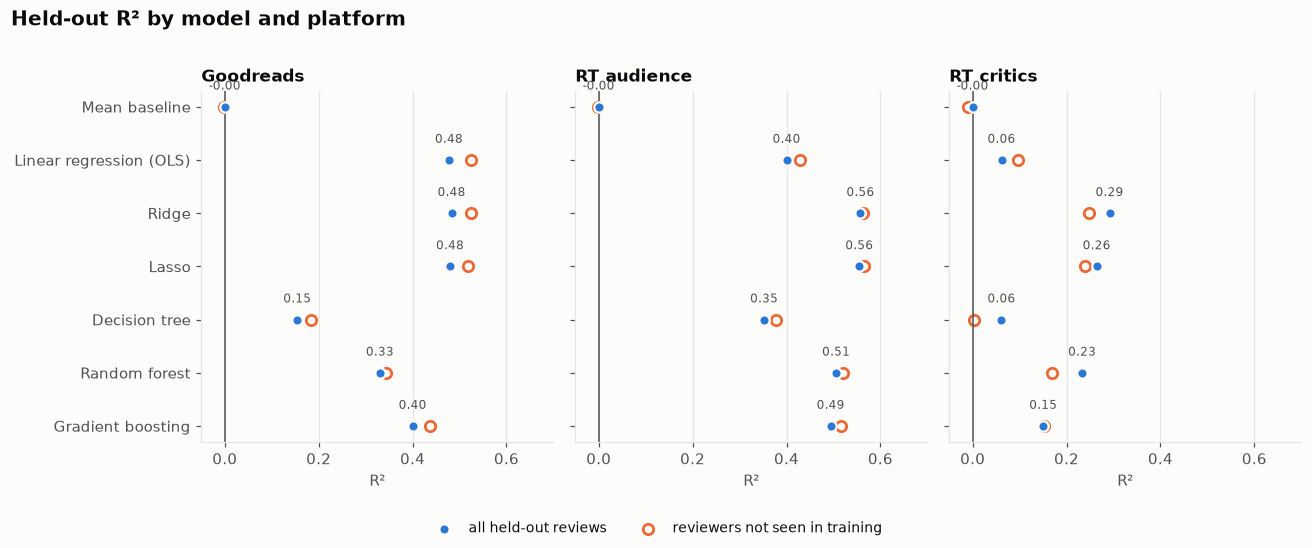

Words Lasso keeps (non-zero coefficients), strongest each way:
  Goodreads    keeps 2,571 of 5,000.  Top +: highly recommended, start finish, loved, highly recommend, masterpiece, favorite.  Top -: poorly, dnf, disappointing, disappointment, boring, worst
  RT audience  keeps 1,464 of 5,000.  Top +: hour minutes, worldwide, government, bad reviews, company, loved.  Top -: worst, garbage, terrible, dumbest, waste, boring
  RT critics   keeps 1,116 of 5,000.  Top +: masterful, masterpiece, miyazaki, rare, human, best.  Top -: worst, inept, bore, willis, incoherent, embarrassing


In [10]:
def plot_model_dots(table, metric, unseen_metric, title, xlabel, order, ref=None, xlim=None):
    platforms = list(results)
    fig, axes = plt.subplots(1, len(platforms), figsize=(12, 0.45 * len(order) + 1.8), sharey=True, sharex=True)
    y = np.arange(len(order))[::-1]
    for ax, platform in zip(axes, platforms):
        t = table[table['platform'] == platform].set_index('model').loc[order]
        ax.scatter(t[metric], y, color=SERIES[0], s=46, zorder=3, edgecolor=SURFACE, linewidth=1.5,
                   label='all held-out reviews')
        ax.scatter(t[unseen_metric], y, facecolor=SURFACE, edgecolor=SERIES[1], s=46, linewidth=1.8, zorder=2,
                   label='reviewers not seen in training')
        for yv, v in zip(y, t[metric]):
            ax.text(v, yv + 0.32, f'{v:.2f}', ha='center', fontsize=8, color=INK2)
        if ref is not None:
            ax.axvline(ref, color=INK2, lw=1)
        if xlim:
            ax.set_xlim(*xlim)
        ax.set_title(platform, fontsize=11)
        ax.set_xlabel(xlabel)
        ax.grid(axis='y', visible=False)
    axes[0].set_yticks(y, order)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc='lower center', ncol=2, fontsize=9)
    fig.suptitle(title, x=0.01, ha='left', fontsize=13, fontweight='bold')
    plt.tight_layout(rect=(0, 0.07, 1, 0.97))
    return fig

fig = plot_model_dots(reg_table, 'R²', 'R², unseen reviewers', 'Held-out R² by model and platform',
                      'R²', list(REGRESSORS), ref=0, xlim=(-0.05, 0.7))
fig.savefig(f'{FIG_DIR}/model-comparison-r2.png', dpi=160, bbox_inches='tight')
plt.show()

print('Words Lasso keeps (non-zero coefficients), strongest each way:')
for label, model in lasso_models.items():
    coefs = pd.Series(model.coef_, index=results[label]['vec'].get_feature_names_out())
    kept = coefs[coefs != 0]
    print(f"  {label:12s} keeps {len(kept):,} of {len(coefs):,}.  "
          f"Top +: {', '.join(kept.nlargest(6).index)}.  Top -: {', '.join(kept.nsmallest(6).index)}")

**Linear models win on text; single trees lose badly.**

| Held-out R² | Goodreads | RT audience | RT critics |
|---|---|---|---|
| Ridge | **0.48** | **0.56** | **0.29** |
| Lasso | 0.48 | 0.56 | 0.26 |
| Random forest | 0.33 | 0.51 | 0.23 |
| Gradient boosting (SVD) | 0.40 | 0.49 | 0.15 |
| Linear regression (OLS) | 0.48 | 0.40 | 0.06 |
| Decision tree | 0.15 | 0.35 | 0.06 |

- **Ridge is best on every platform.** With 5,000 sparse word features, a rating is mostly a sum of many small word signals, which is exactly what a linear model captures.
- **Lasso nearly matches Ridge with a fraction of the vocabulary.** It keeps 1,464 of 5,000 terms for RT audiences and 1,116 for critics (about a quarter), so it's the model to pick when a short, readable word list matters more than the last point of R². On Goodreads it keeps 2,571; there the best penalty was the smallest tried and the solver stopped just short of full convergence, so treat that row as approximate.
- **OLS only works when data is plentiful.** With 98k Goodreads reviews it nearly matches Ridge (0.48). With 12k critic reviews it collapses to 0.06, the clearest case for regularization.
- **Trees struggle with sparse text.** Each split asks about one word, and any one word separates out only a small share of reviews, so a tree needs many splits to say anything. A random forest averages away much of that (0.33–0.51), but still trails Ridge. Gradient boosting on 300 compressed SVD components does better than the forest on Goodreads but loses detail on short critic blurbs.
- **Fitting cost:** Ridge fits in seconds. Lasso took about 210 seconds on Goodreads and trees about a minute, for worse scores.

### 1.5 Comparing model families: positive or negative review?

The same reviews turned into a yes/no question, using each platform's own idea of a positive review:

| Platform | Positive means |
|---|---|
| Goodreads | 4 or 5 stars |
| RT audience | 3.5 stars or more (the cut-off RT uses for its audience score) |
| RT critics | marked Fresh |

The main metric is **ROC-AUC**: the chance that the model ranks a random positive review above a random negative one (0.5 is guessing, 1.0 is perfect). Accuracy and macro-F1 use a 0.5 probability cut-off. Settings are tuned on the same inner validation split, by AUC.

Goodreads    72% of training reviews are positive
RT audience  65% of training reviews are positive
RT critics   68% of training reviews are positive


Goodreads: done


RT audience: done


RT critics: done


platform,Goodreads,RT audience,RT critics
model,,,
Majority class,0.500,0.500,0.500
Logistic regression (L2),0.891,0.907,0.830
"Logistic regression (L1, Lasso)",0.890,0.899,0.812
Naive Bayes,0.868,0.911,0.835
Decision tree,0.717,0.778,0.624
Random forest,0.850,0.880,0.783
Gradient boosting,0.848,0.864,0.728


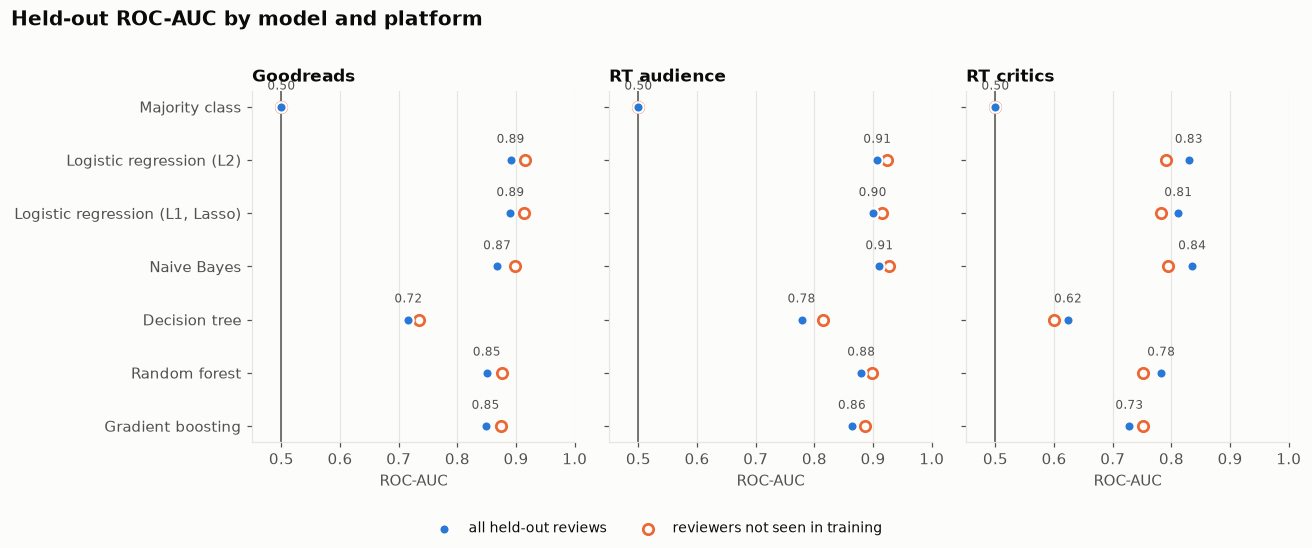

In [11]:
POSITIVE = {
    'Goodreads':   lambda d: d['rating_normalized'] >= 0.75,
    'RT audience': lambda d: d['rating_normalized'] >= (3.5 - 0.5) / 4.5 - 1e-9,
    'RT critics':  lambda d: d['is_positive'] == 1,
}
for label, r in results.items():
    positive = POSITIVE[label](r['df']).astype(int).to_numpy()
    r['c_train'], r['c_test'] = positive[r['train_idx']], positive[r['test_idx']]
    print(f"{label:12s} {r['c_train'].mean():.0%} of training reviews are positive")

auc_of = lambda m, X, y: roc_auc_score(y, m.predict_proba(X)[:, 1])
CLASSIFIERS = {
    'Majority class':                   (lambda: DummyClassifier(strategy='most_frequent'), [{}], False),
    'Logistic regression (L2)':         (lambda: LogisticRegression(max_iter=2000),
                                         [{'C': c} for c in (0.25, 1, 4)], False),
    'Logistic regression (L1, Lasso)':  (lambda: LogisticRegression(solver='liblinear', l1_ratio=1),
                                         [{'C': c} for c in (0.25, 1, 4)], False),
    'Naive Bayes':                      (MultinomialNB, [{'alpha': a} for a in (0.1, 0.3, 1)], False),
    'Decision tree':                    (lambda: DecisionTreeClassifier(min_samples_leaf=20, random_state=SEED),
                                         [{'max_depth': d} for d in (8, 16, 32)], False),
    'Random forest':                    (lambda: RandomForestClassifier(n_estimators=100, max_features='sqrt',
                                                                        min_samples_leaf=3, n_jobs=-1,
                                                                        random_state=SEED), [{}], False),
    'Gradient boosting':                (lambda: HistGradientBoostingClassifier(max_iter=200, learning_rate=0.2,
                                                                               early_stopping=True,
                                                                               random_state=SEED), [{}], True),
}

clf_rows = []
for label, r in results.items():
    u = r['unseen']
    for name, (make, grid, dense) in CLASSIFIERS.items():
        start = time.time()
        Xtr, Xte = (r['S_train'], r['S_test']) if dense else (r['X_train'], r['X_test'])
        model, best = tune_on_inner_split(make, grid, Xtr, r['c_train'], r['groups_train'], auc_of)
        prob = model.predict_proba(Xte)[:, 1]
        pred = (prob >= 0.5).astype(int)
        y = r['c_test']
        clf_rows.append({'platform': label, 'model': name, 'ROC-AUC': roc_auc_score(y, prob),
                         'accuracy': accuracy_score(y, pred), 'macro-F1': f1_score(y, pred, average='macro'),
                         'ROC-AUC, unseen reviewers': roc_auc_score(y[u], prob[u]),
                         'settings': ', '.join(f'{k}={v}' for k, v in best.items()) or '-',
                         'seconds': round(time.time() - start)})
    print(f'{label}: done')

clf_table = pd.DataFrame(clf_rows)
display(clf_table.pivot(index='model', columns='platform', values='ROC-AUC').loc[list(CLASSIFIERS)]
        .style.format('{:.3f}').set_caption('Held-out ROC-AUC by model'))
display(clf_table.set_index(['platform', 'model'])
        [['ROC-AUC', 'accuracy', 'macro-F1', 'ROC-AUC, unseen reviewers', 'settings', 'seconds']]
        .style.format({c: '{:.3f}' for c in ['ROC-AUC', 'accuracy', 'macro-F1', 'ROC-AUC, unseen reviewers']}))

fig = plot_model_dots(clf_table, 'ROC-AUC', 'ROC-AUC, unseen reviewers', 'Held-out ROC-AUC by model and platform',
                      'ROC-AUC', list(CLASSIFIERS), ref=0.5, xlim=(0.45, 1.0))
plt.show()

#### A decision tree you can read

A depth-3 tree on the critic reviews, fresh vs. rotten. Each split is a word's TF-IDF weight. A rule like `worst <= 0.05` effectively means "the review doesn't use *worst*". Deep trees score better (see the table above), but this one shows the logic a tree learns.

Depth-3 tree, held-out ROC-AUC 0.517, accuracy 0.691 (majority class: 0.681)


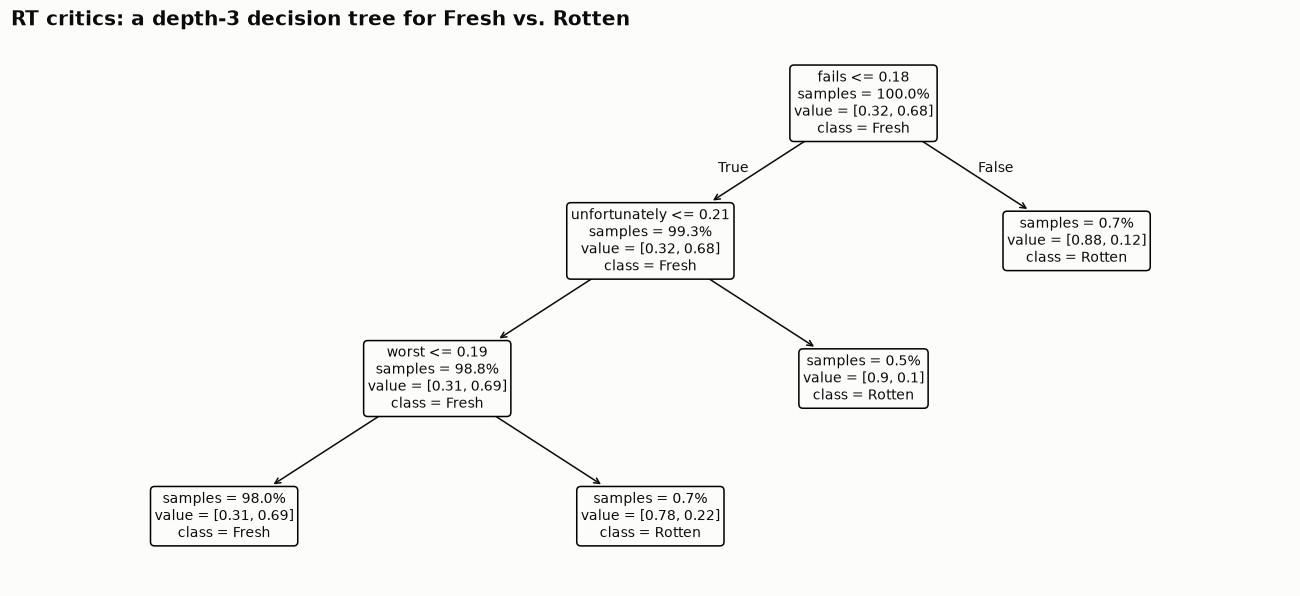

In [12]:
r = results['RT critics']
shallow = DecisionTreeClassifier(max_depth=3, min_samples_leaf=50, random_state=SEED).fit(r['X_train'], r['c_train'])
print(f"Depth-3 tree, held-out ROC-AUC {roc_auc_score(r['c_test'], shallow.predict_proba(r['X_test'])[:, 1]):.3f}, "
      f"accuracy {accuracy_score(r['c_test'], shallow.predict(r['X_test'])):.3f} "
      f"(majority class: {max(r['c_test'].mean(), 1 - r['c_test'].mean()):.3f})")
fig, ax = plt.subplots(figsize=(15, 6.5))
plot_tree(shallow, feature_names=r['vec'].get_feature_names_out(), class_names=['Rotten', 'Fresh'],
          filled=False, impurity=False, proportion=True, rounded=True, precision=2, fontsize=9, ax=ax)
ax.set_title('RT critics: a depth-3 decision tree for Fresh vs. Rotten')
plt.show()

**Positive vs. negative is an easier question than the exact rating.** The best models reach a ROC-AUC of 0.89 on Goodreads, 0.91 for RT audiences and 0.84 for critics: given one positive and one negative review, they rank the positive one higher about 9 times in 10 (8 in 10 for critics).

| Held-out ROC-AUC | Goodreads | RT audience | RT critics |
|---|---|---|---|
| Logistic regression (L2) | **0.891** | 0.907 | 0.830 |
| Logistic regression (L1, Lasso) | 0.890 | 0.899 | 0.812 |
| Naive Bayes | 0.868 | **0.911** | **0.835** |
| Random forest | 0.850 | 0.880 | 0.783 |
| Gradient boosting (SVD) | 0.848 | 0.864 | 0.728 |
| Decision tree | 0.717 | 0.778 | 0.624 |
| Majority class | 0.500 | 0.500 | 0.500 |

- **The same ranking as for regression.** Linear models and Naive Bayes lead, ensembles follow, and a single deep tree is last. Naive Bayes, the oldest and fastest model here (under a second), edges out logistic regression on the two shorter-text platforms.
- **Accuracy needs context.** About 70% of reviews are positive on every platform, so always guessing "positive" is already 65–72% accurate. Logistic regression reaches 85% on Goodreads and audiences and 78% on critics. Macro-F1 (0.79 / 0.82 / 0.70) shows it gets both classes right, not just the common one.
- **Critics remain the hardest voice** on every model, matching the regression results.
- **The readable tree shows why trees fail on text.** Its three splits (*fails*, *unfortunately*, *worst*) are sensible, but each one separates out under 1% of critic reviews. The tree sends 98% of reviews down one branch and labels them all Fresh, so its held-out AUC is 0.52, barely above guessing. Text signal is spread thinly across thousands of words, which suits a linear model.

### 1.6 Which words matter, with uncertainty

Coefficients come from the Ridge model fit on the training titles. To get 95% intervals, the training **titles** are resampled with replacement 200 times and the model refit each time. Resampling titles rather than reviews matters: a phrase that only appears in reviews of one film gets a wide interval, because it disappears whenever that film isn't drawn.

Only words whose interval excludes zero are shown.

In [13]:
def bootstrap_coefs(r, n_boot=N_BOOT):
    X, y, g = r['X_train'], r['y_train'], r['groups_train']
    titles, which = np.unique(g, return_inverse=True)
    rng = np.random.default_rng(SEED)
    draws = np.empty((n_boot, X.shape[1]), dtype=np.float32)
    for b in range(n_boot):
        weight = np.bincount(rng.integers(0, len(titles), len(titles)), minlength=len(titles))[which]
        keep = weight > 0
        draws[b] = Ridge(alpha=r['alpha']).fit(X[keep], y[keep], sample_weight=weight[keep]).coef_
    lo, hi = np.percentile(draws, [2.5, 97.5], axis=0)
    out = pd.DataFrame({'coef': r['ridge'].coef_, 'lo': lo, 'hi': hi}, index=r['vec'].get_feature_names_out())
    out['significant'] = (out['lo'] > 0) | (out['hi'] < 0)
    return out

word_coefs = {}
for label, r in results.items():
    start = time.time()
    word_coefs[label] = bootstrap_coefs(r)
    sig = word_coefs[label]['significant']
    print(f"{label:12s} {sig.sum():,} of {len(sig):,} terms have a 95% interval excluding 0 ({time.time() - start:.0f}s)")

Goodreads    1,592 of 5,000 terms have a 95% interval excluding 0 (108s)


RT audience  1,173 of 5,000 terms have a 95% interval excluding 0 (2s)


RT critics   1,061 of 5,000 terms have a 95% interval excluding 0 (2s)


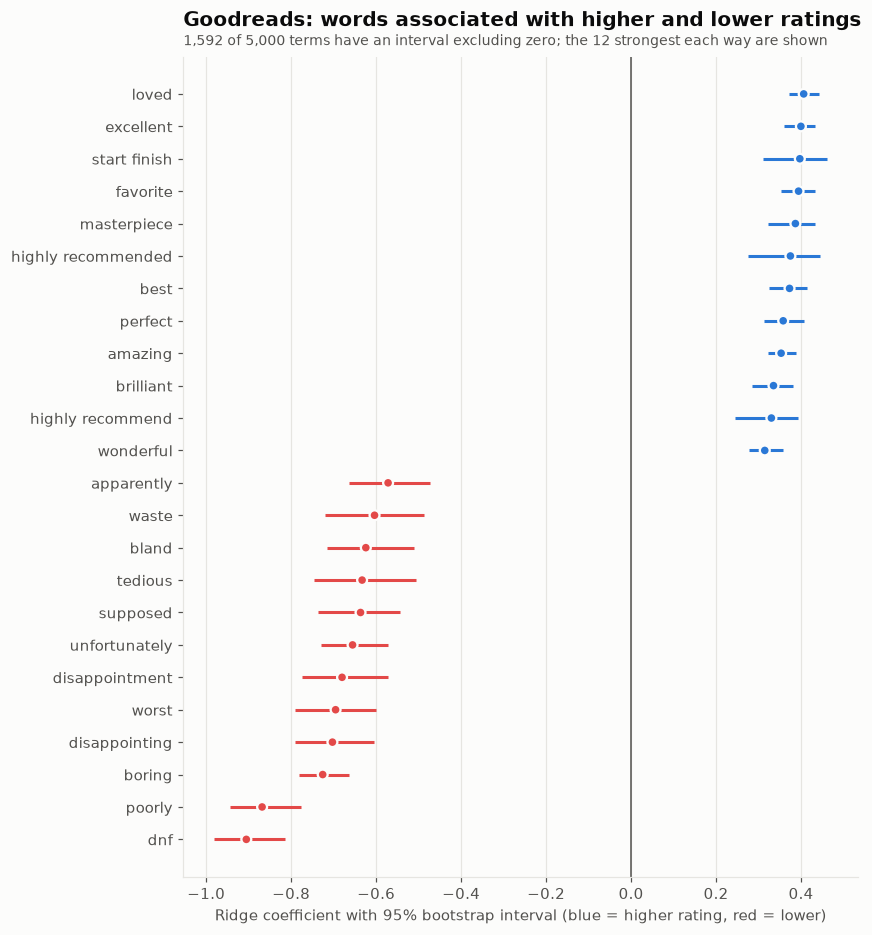

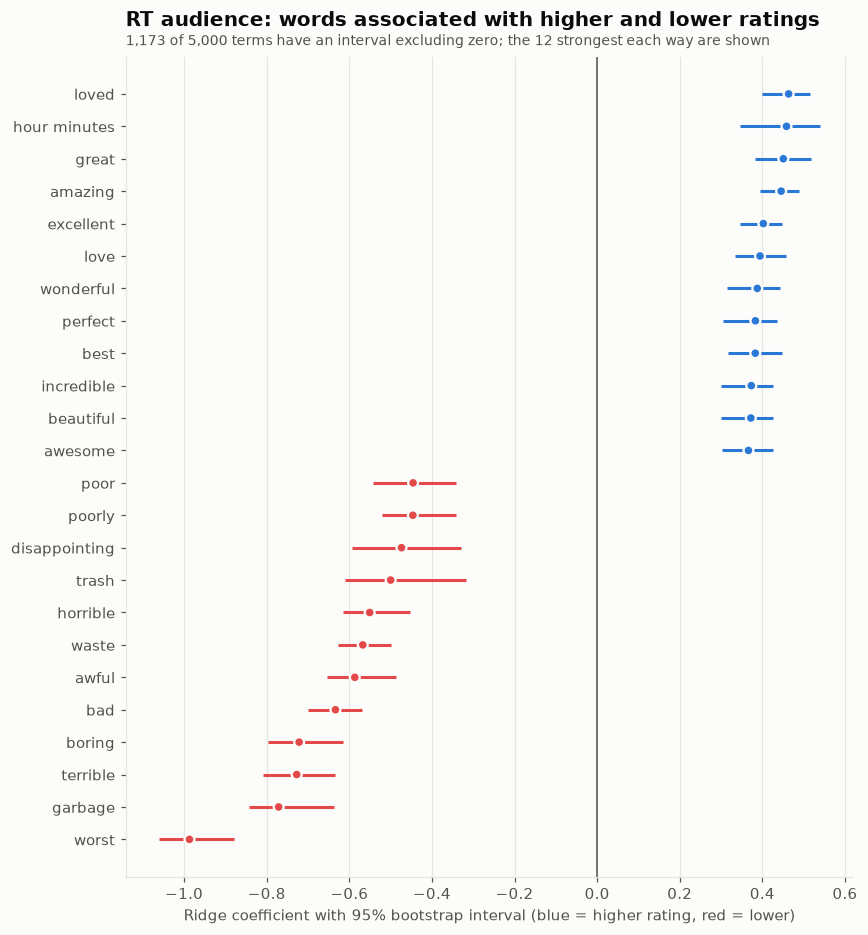

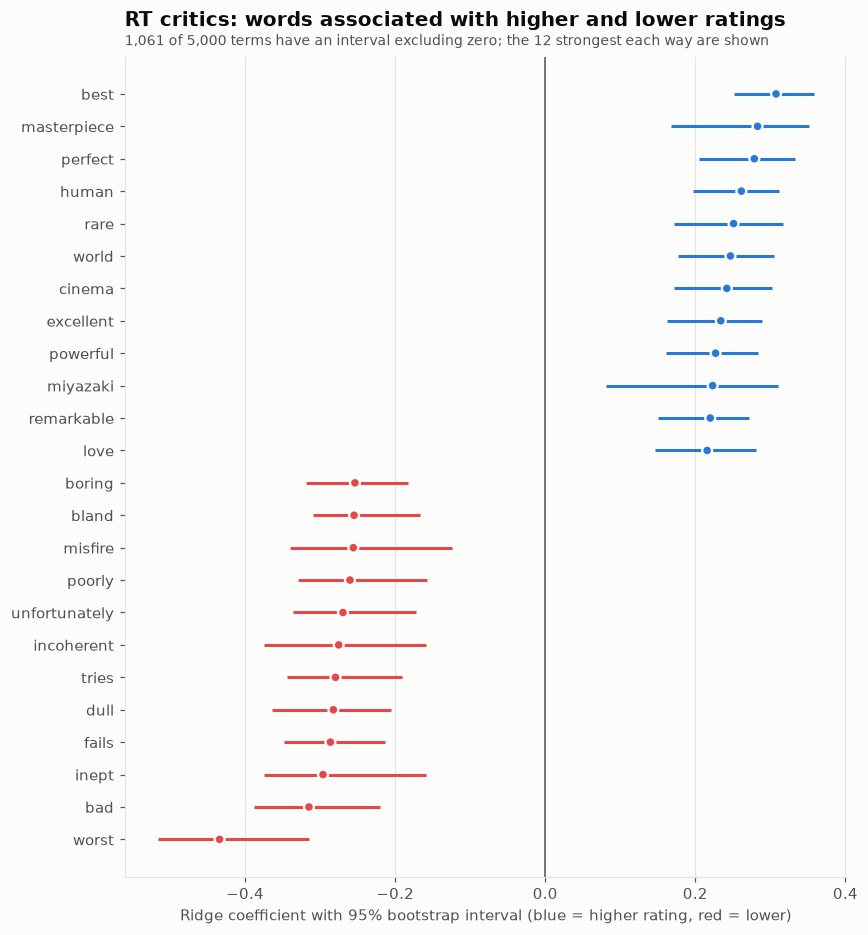

In [14]:
def plot_coef_ci(table, title, xlabel, n=12, subtitle=None):
    sig = table[table['significant']]
    data = pd.concat([sig.nsmallest(n, 'coef'), sig.nlargest(n, 'coef')]).drop_duplicates().sort_values('coef')
    colors = np.where(data['coef'] > 0, POS, NEG)
    y = np.arange(len(data))
    fig, ax = plt.subplots(figsize=(8, 0.3 * len(data) + 1.4))
    ax.hlines(y, data['lo'], data['hi'], color=colors, lw=2)
    ax.scatter(data['coef'], y, color=colors, s=42, zorder=3, edgecolor=SURFACE, linewidth=1.5)
    ax.axvline(0, color=INK2, lw=1)
    ax.set_yticks(y, data.index)
    ax.grid(axis='y', visible=False)
    ax.set_xlabel(xlabel)
    ax.set_title(title, pad=20 if subtitle else 6)
    if subtitle:
        ax.text(0, 1.01, subtitle, transform=ax.transAxes, color=INK2, fontsize=9, va='bottom')
    plt.tight_layout()
    plt.show()

for label, table in word_coefs.items():
    plot_coef_ci(table, f'{label}: words associated with higher and lower ratings',
                 'Ridge coefficient with 95% bootstrap interval (blue = higher rating, red = lower)',
                 subtitle=f"{table['significant'].sum():,} of {len(table):,} terms have an interval excluding zero; "
                          'the 12 strongest each way are shown')

### 1.7 Do the same words mean the same thing everywhere?

The 10 strongest significant words each way from each platform, with their coefficient on every platform. Blank cells mean the word isn't in that platform's vocabulary; `·` marks a coefficient whose interval includes zero.

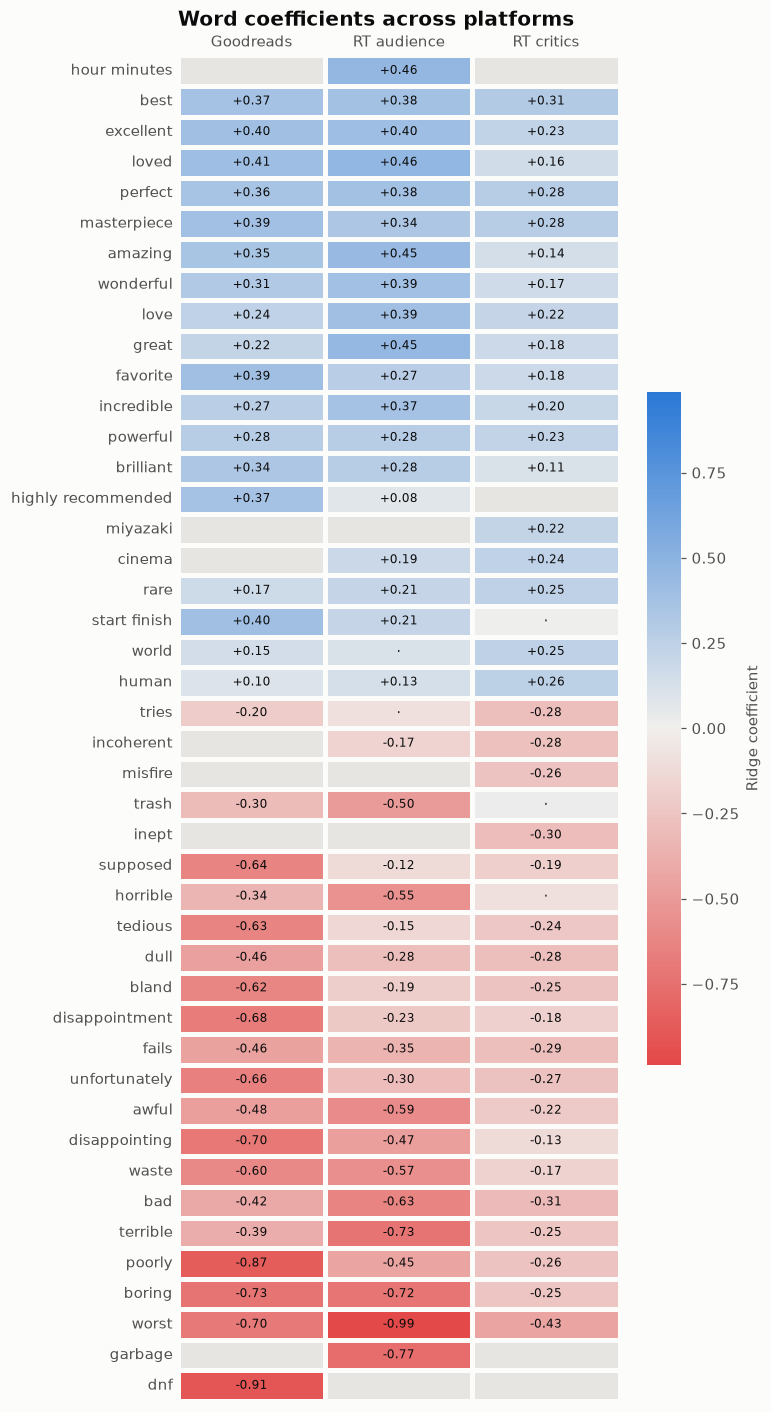

In [15]:
key_words = set()
for table in word_coefs.values():
    sig = table[table['significant']]
    key_words |= set(sig.nlargest(10, 'coef').index) | set(sig.nsmallest(10, 'coef').index)

coef_grid = pd.DataFrame({label: t['coef'].reindex(sorted(key_words)) for label, t in word_coefs.items()})
sig_grid = pd.DataFrame({label: t['significant'].reindex(sorted(key_words)) for label, t in word_coefs.items()})
order = coef_grid.mean(axis=1).sort_values(ascending=False).index
coef_grid, sig_grid = coef_grid.loc[order], sig_grid.loc[order]
labels = coef_grid.map(lambda v: '' if pd.isna(v) else f'{v:+.2f}')
labels = labels.where(sig_grid.fillna(False).astype(bool), labels.map(lambda s: s and '·'))

limit = np.nanmax(np.abs(coef_grid.to_numpy()))
fig, ax = plt.subplots(figsize=(7, 0.26 * len(coef_grid) + 1.5))
ax.set_facecolor(GRID)
sns.heatmap(coef_grid, annot=labels, fmt='', cmap=DIVERGING, vmin=-limit, vmax=limit, center=0,
            linewidths=2, linecolor=SURFACE, cbar_kws={'label': 'Ridge coefficient', 'shrink': 0.5},
            annot_kws={'fontsize': 8, 'color': INK}, ax=ax)
ax.set_title('Word coefficients across platforms')
ax.set_xlabel('')
ax.set_ylabel('')
ax.tick_params(axis='x', labeltop=True, labelbottom=False, length=0)
ax.tick_params(axis='y', length=0)
plt.tight_layout()
plt.show()

### 1.8 Words that separate high and low ratings (descriptive)

A simpler, model-free view. Reviews in each platform's top quarter of ratings are compared with the bottom quarter, counting how often each word appears per 1,000 reviews. This is descriptive only: it has no held-out test or intervals.

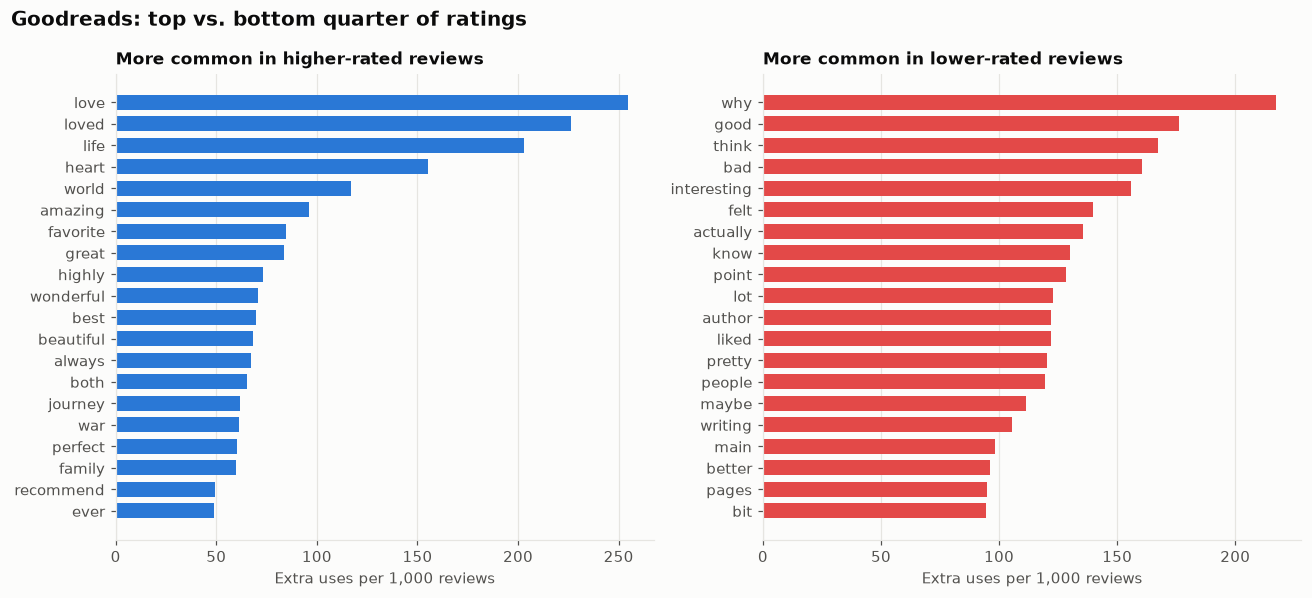

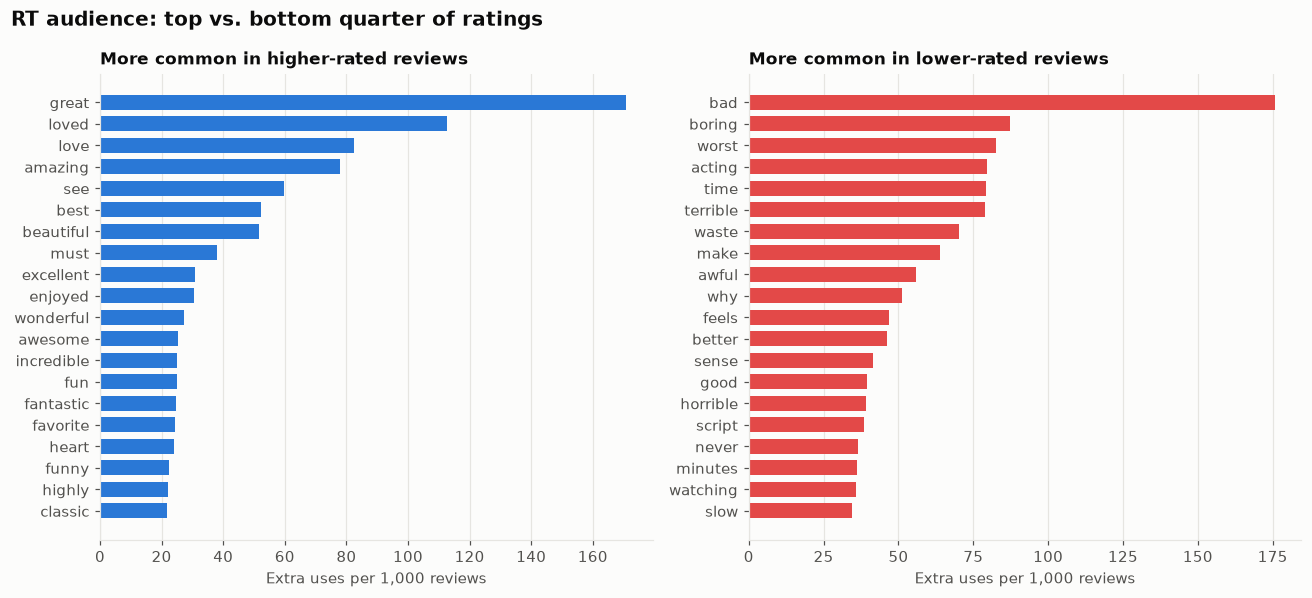

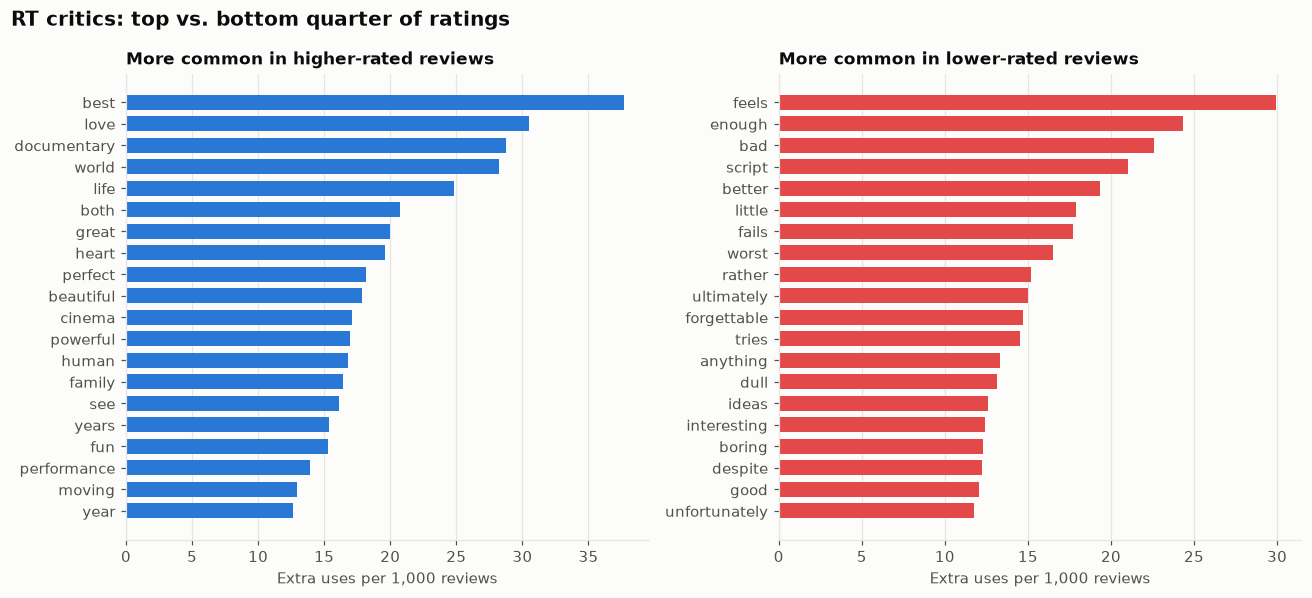

In [16]:
TIER_STOP = set('''the a an and or but in on at to for of is it was with that this are be as by not from have has had i
my me we you he she they so just its no do did would could should been were all can will than very about what which
there their them if up out one more also like how when who some into her his our your only other over after then two
those where get got much because really even any most many own off being through down between each few such here
these don doesn didn way well too still made movie film book story read watch watched reading movies films books
stories characters character plot scene scenes end isn wasn aren couldn wouldn won let things thing going something
nothing'''.split())

def tier_words(df, label, top_n=20):
    q25, q75 = df['rating_normalized'].quantile([0.25, 0.75])
    def rate(texts):
        counts = Counter(w for t in texts for w in re.findall(r'[a-z]{3,}', t.lower()) if w not in TIER_STOP)
        return pd.Series(counts) / max(len(texts), 1) * 1000
    high = rate(df.loc[df['rating_normalized'] >= q75, 'review_text'])
    low = rate(df.loc[df['rating_normalized'] <= q25, 'review_text'])
    vocab = high.nlargest(200).index.union(low.nlargest(200).index)
    diff = (high.reindex(vocab).fillna(0) - low.reindex(vocab).fillna(0)).sort_values()

    fig, axes = plt.subplots(1, 2, figsize=(12, 5.5))
    for ax, part, color, side in [(axes[0], diff.tail(top_n), POS, 'higher'),
                                  (axes[1], diff.head(top_n)[::-1], NEG, 'lower')]:
        ax.barh(part.index, part.abs(), color=color, height=0.7)
        ax.set_title(f'More common in {side}-rated reviews', fontsize=11)
        ax.set_xlabel('Extra uses per 1,000 reviews')
        ax.grid(axis='y', visible=False)
    fig.suptitle(f'{label}: top vs. bottom quarter of ratings', x=0.01, ha='left',
                 fontsize=13, fontweight='bold')
    plt.tight_layout()
    plt.show()

for label, df in q1.items():
    tier_words(df, label)

### 1.9 Error analysis: the 20 worst held-out predictions per platform

In [17]:
worst = {}
for label, r in results.items():
    t = r['test']
    worst[label] = (t.assign(abs_error=t['error'].abs()).nlargest(20, 'abs_error')
                     [['rating_normalized', 'predicted', 'error', 'word_count', 'review_text']]
                     .rename(columns={'rating_normalized': 'actual'})
                     .assign(review_text=lambda d: d['review_text'].str.slice(0, 220)))
    print(f"\n{label}: mean absolute error {t['error'].abs().mean():.3f}; "
          f"{(t['error'] > 0).mean():.0%} of held-out predictions are too high")
    display(worst[label].round(2))


Goodreads: mean absolute error 0.167; 40% of held-out predictions are too high


,actual,predicted,error,word_count,review_text
78135,0.0,1.00,1.00,38,very dark. very pessimistic. had to read this for a class that i'm indifferent to. will not be reading again and am now worried about the end of humanity every day. would not recommend for someone with anxiety.
19124,0.0,1.00,1.00,346,"This is my husband's favorite book. Obviously he is more effective than I am. Dividing my life into squares, writing in those squares the things I have to do, then doing the ""most important"" may make me effective, bu..."
10447,0.0,0.95,0.95,417,"This is probably the best book I have read that describes in clear, real detail the transformation of someone moving from privilege and elite status, to an unmentionable. There isn't any trite descriptions of realizi..."
19478,0.0,0.87,0.87,319,"This book is a distortion of Jesus' teaching. We can expect to have trials and suffering in this life, our only hope is that Jesus has overcome. That's a promise for eternity (eschatological), for a time when the bel..."
76861,0.0,0.87,0.87,104,"This man is such a hypocrite! He is preaching respect for the wild outdoor spaces, then he has the audacity to relate how he kills a little hidden rabbit just for the fun of it! His philosophy of locking up wild plac..."
83220,0.0,0.86,0.86,43,Fantastic book if you want to learn how to be an industrial engineer who sacrifices every bit of their humanity and all personal relationships to make sure your factory runs at tip top efficiency. Don't make an engin...
59192,0.0,0.86,0.86,10,one of those rare situations where the show is better
88937,0.0,0.86,0.86,29,"It was ok.But Jack was all like this.... WERE FAILING MERLIN'S MISSION,WHICH CLOCK IS MIDNIGHT? NONE OF THEM ARE RIGHT!!!!!!!!!!!!!!!!!!!!!Oh the Horror!!! He worries mostly in all the books."
71649,0.0,0.86,0.86,647,"The one star rating does not mean I don't recommend reading The Social Contract . Everyone should. It's that important, that influential and reading this was certainly eye-opening. One star does not mean this was ted..."
32432,0.0,0.85,0.85,135,"So ... I'm the outlier. I cannot abide Flavia de Luce - yes, the same Flavia de Luce that everyone else in the reading universe - or at least the subset of those who enjoy mysteries - loves, adores, enjoys. For month..."



RT audience: mean absolute error 0.180; 40% of held-out predictions are too high


,actual,predicted,error,word_count,review_text
5206,0.00,1.00,1.00,6,Not a great movie at all.
1421,0.00,0.80,0.80,9,WASNT REALLY THAT GOOD AT ALL IN MY OPINION
12260,0.00,0.79,0.79,9,I think Jesus hates humanity because of this film
7608,0.00,0.74,0.74,20,"Full of lies. It portrayed God's imagine in another way. Please know He is a good Father, Merciful and Loving."
3052,1.00,0.26,-0.74,18,"I had zero hopes going in and walked out very surprised, that's how you carry on a legeacy."
1791,0.00,0.73,0.73,5,Absolute dogshit of a movie...
4934,0.00,0.73,0.73,5,"Absolutely not, do not recommend"
13716,0.00,0.73,0.73,24,"If you feel like watching a corpulent Steven Segal huff, puff and wheeze his way into a heart attack this film is for you."
10303,0.11,0.84,0.73,159,"Hire a Bitcoin Recovery Expert Solution: Best Crypto Recovery Services: Please be careful when individuals solicit your funds or when investment platforms promise extraordinary gains. Approximately one month ago, I i..."
12257,0.00,0.72,0.72,11,I loved the part where Luis tried to commit check fraud



RT critics: mean absolute error 0.137; 47% of held-out predictions are too high


,actual,predicted,error,word_count,review_text
5526,0.00,0.66,0.66,37,"Perry's intentions might have been well-positioned for some time, until a Giallo-esque red herring makes its final reveal during the movie's climax and derails any goodwill he had when he slowly introduced audiences ..."
13466,0.10,0.75,0.65,7,A dream of dark and troubling things.
10600,0.00,0.62,0.62,9,There truly is no reason to see this film.
13669,0.00,0.61,0.61,24,"If this is the kind of garbage kids are watching and absorbing with glee today, no wonder the country is in such a mess."
13722,0.00,0.59,0.59,8,"It's official. We want the Oscar back, Cuba."
14260,0.10,0.68,0.58,10,What in the hell is going on with John Travolta?
1086,0.10,0.67,0.57,21,"Like an appalling first date, this movie smugly declares itself smart and funny and then delivers all evidence to the contrary."
10010,0.00,0.57,0.57,30,"Unplanned will make you writhe in agony over how such an ugly, malicious and potentially dangerous piece of religious and political propaganda could have made its way into this world."
15574,0.20,0.74,0.54,15,"This mashup of magical realism, gratuitous violence and sentimentality is an atrocity in filmic form."
7271,0.20,0.74,0.54,7,"Wild, disturbing, and it made no sense."


**What goes wrong.** I read all 60 rows above. In 59 of them the model predicted a high rating for a low one. Ratings skew positive and the model leans toward the average, so its biggest misses are pans that don't use the usual pan vocabulary.

| Cause | Goodreads | RT audience | RT critics | Example |
|---|---|---|---|---|
| **Negation** (TF-IDF sees *good*, misses *not*) | 1 | 8 | 1 | "Not a great movie at all." predicted 1.00, actual 0.00 |
| **Moral, religious or political objection** in neutral words | 6 | 4 | 6 | "This book is a distortion of Jesus' teaching..." |
| **Sarcasm and irony** | 3 | 4 | 0 | "Fantastic book if you want to learn how to be an industrial engineer who sacrifices every bit of their humanity..." |
| **Witty or figurative pans** with no negative words | 0 | 0 | 7 | "It's official. We want the Oscar back, Cuba." |
| **Setup contradicts the verdict** (praise words, then a pan, or the reverse) | 3 | 1 | 4 | "Cinderella is a tired tale... it really has to blow me away." |
| **Too short, slang, or needs context** | 5 | 2 | 0 | "these two would definitely get divorced" |
| **Text and rating disagree** (praise with a one-star rating) | 2 | 0 | 0 | "The one star rating does not mean I don't recommend reading The Social Contract." |
| **Spam** | 0 | 1 | 0 | a crypto-recovery ad posted as an audience review |
| **Rare vocabulary** | 0 | 0 | 2 | "an atrocity in filmic form" |

What this means for the next model:
- **Negation and sarcasm** are word-order problems. They are the main case for sentence embeddings or a fine-tuned transformer (Phase 3), which read *not good* as one idea.
- **Critic errors are mostly style.** Critics pan films with wit and reference rather than "bad" or "boring", which is why critic text explains less (R² 0.29) than audience text (0.56).
- **Ideological objections** are hard for any text model. The review attacks the book's message, not its craft.
- **A reviewer leak the title split misses.** The RT audience phrase *hour minutes* (+0.46) comes from one user who posts templated reviews on many films ("Success in 01 hour, 40 minutes... Ages 13 and older!!!"). The same reviewer can appear in both training and test. The top 10 audience reviewers wrote only 3.3% of reviews, so the effect on scores is small, but the next version should also group by reviewer.

## Conclusion: Research Question 1

**Review text predicts ratings well for readers and audiences, and only moderately for critics. On held-out titles, Ridge on review text explains 48% of the variance in Goodreads ratings, 56% for RT audiences and 29% for RT critics.**

| | Goodreads | RT audience | RT critics |
|---|---|---|---|
| Class version, scored on its training data | 0.52 | 0.78 | 0.64 |
| Class version, held-out titles | 0.47 | 0.31 | **0.05** |
| Baseline: title's published average | 0.06 | 0.30 | **0.50** |
| **Ridge on review text** (held-out) | **0.48** | **0.56** | **0.29** |
| Ridge on text + title average (held-out) | 0.50 | 0.60 | 0.55 |
| Grouped CV R² on training titles (mean ± sd) | 0.46 ± 0.01 | 0.54 ± 0.01 | 0.28 ± 0.01 |
| Typical error (MAE), in stars | 0.67 of 4 | 0.81 of 4.5 | 0.69 of 5 |

### What changed from the class version
- **The RT numbers were mostly overfitting.** With 5,000 features and 12–15k reviews, unregularized regression nearly memorizes the training set. On new films the critic model's R² falls from 0.64 to 0.05, and the audience model's from 0.78 to 0.31. Ridge recovers 0.29 and 0.56. Goodreads, with eight times more reviews, was barely affected (0.52 → 0.47).
- **The class report's "highest R²" platform was the most overfit**, not the most predictable. The film-specific terms it flagged (*walt disney*, *zachary*) don't survive a title-level split with intervals.

### Findings
- **Ridge is the best of seven model families** for predicting the rating on every platform (1.4). Lasso comes close while keeping a quarter to half of the vocabulary. Random forests and gradient boosting trail, and a single decision tree is worst. As a yes/no question (positive or not), logistic regression and Naive Bayes reach ROC-AUC 0.83–0.91 (1.5).
- **Scores don't depend on knowing the reviewer** (1.3). Reviews from people absent from training score as well as the rest.
- **Readers disagree about the same book; critics converge.** Knowing which book a review is about explains only 6% of Goodreads ratings, while the words explain 48%. For critics it's the reverse: the film's average critic score (0.50) beats the critic's own words (0.29). Critic blurbs are short (median 25 words) and measured, and critics largely agree on a film.
- **Critics' words carry smaller signals.** Their strongest coefficients are about half the size of audiences' (*worst* −0.43 vs. −0.99). Critic negatives are craft diagnoses: *inept*, *incoherent*, *misfire*, *fails*, *tries*. Positives lean on scale and seriousness: *masterpiece*, *human*, *rare*, *world*, *cinema*. Audiences use blunt verdicts: *worst*, *garbage*, *terrible*, *boring*, *loved*, *amazing*.
- **Goodreads has its own vocabulary of disappointment.** *dnf* (did not finish, −0.91) and *poorly* (−0.87) are its two strongest terms, ahead of *boring* and *worst*. The class finding that **skepticism words** predict low ratings holds with intervals: *supposed* (−0.64) and *apparently* (−0.57) are both clearly below zero.
- **Engagement phrases matter on Goodreads.** *start finish* (+0.40) ranks with *loved* and *excellent*.
- **Intervals filter out noise.** Between a fifth and a third of the 5,000 terms have an interval excluding zero (1,592 Goodreads, 1,173 audience, 1,061 critic). One director's name, *miyazaki* (+0.22), survives because it spans several films.
- **The model's errors share causes** (see 1.9): negation, sarcasm, objections to a book's or film's message, and witty critic pans. These point to word-order-aware models as the next step.

# Research Question 2: Genre and the critic–audience split

**Which genres are associated with higher or lower ratings, and which genres do critics and audiences disagree on?**

### Method
- **Films:** the 2,454 Rotten Tomatoes films with both a Tomatometer and an audience score. Films missing either are dropped, not median-filled. Three targets on the same 0–100 point scale: critic score, audience score, and the **gap** (critic − audience). The gap answers the disagreement question directly.
- **Books:** Goodreads average rating rescaled to 0–100 points ((rating − 1) / 4 × 100). Format and meta tags (Audiobook, Ebooks, Book Club) are dropped.
- Only genres with at least 30 titles. Ridge regression on genre indicators (a title can have several), penalty chosen by 5-fold CV repeated 3 times, with the mean ± sd R² across folds reported.
- 95% intervals from 1,000 bootstrap resamples of titles.

A coefficient is the average difference in score for titles with that genre, holding the title's other genres fixed. It is an association: genre also stands in for budget, audience and release strategy.

In [18]:
def genre_matrix(lists, min_titles=MIN_TITLES, drop=()):
    mlb = MultiLabelBinarizer()
    X = pd.DataFrame(mlb.fit_transform(lists), columns=mlb.classes_, index=lists.index)
    keep = [g for g in X.columns if X[g].sum() >= min_titles and g not in drop]
    return X[keep]

def fit_genre_model(X, y, name, n_boot=1000):
    cv = RepeatedKFold(n_splits=5, n_repeats=3, random_state=SEED)
    cv_scores = {a: cross_val_score(Ridge(alpha=a), X, y, cv=cv, scoring='r2') for a in GENRE_ALPHAS}
    alpha = max(cv_scores, key=lambda a: cv_scores[a].mean())
    rng = np.random.default_rng(SEED)
    Xv, n = X.to_numpy(), len(y)
    draws = np.array([Ridge(alpha=alpha).fit(Xv[idx], y[idx]).coef_
                      for idx in (rng.integers(0, n, n) for _ in range(n_boot))])
    lo, hi = np.percentile(draws, [2.5, 97.5], axis=0)
    table = pd.DataFrame({'coef': Ridge(alpha=alpha).fit(Xv, y).coef_, 'lo': lo, 'hi': hi,
                          'titles': Xv.sum(axis=0)}, index=X.columns)
    table['significant'] = (table['lo'] > 0) | (table['hi'] < 0)
    summary = {'model': name, 'titles': n, 'genres': X.shape[1], 'alpha': alpha,
               'CV R² mean': cv_scores[alpha].mean(), 'CV R² sd': cv_scores[alpha].std(),
               'significant genres': int(table['significant'].sum())}
    return table, summary

films = movies.dropna(subset=['tomatometer', 'audience_score'])
films = films[films['genres_list'].str.len() > 0]
X_films = genre_matrix(films['genres_list'])
film_targets = {
    'RT critics':           films['tomatometer'].to_numpy(),
    'RT audience':          films['audience_score'].to_numpy(),
    'Critic − audience gap': (films['tomatometer'] - films['audience_score']).to_numpy(),
}

tagged_books = books[books['genres_list'].str.len() > 0]
X_books = genre_matrix(tagged_books['genres_list'], drop={'Audiobook', 'Ebooks', 'Book Club'})
y_books = ((tagged_books['avg_rating'] - 1) / 4 * 100).to_numpy()

genre_models, summaries = {}, []
for name, y in film_targets.items():
    genre_models[name], s = fit_genre_model(X_films, y, name)
    summaries.append(s)
genre_models['Goodreads readers'], s = fit_genre_model(X_books, y_books, 'Goodreads readers')
summaries.append(s)

display(pd.DataFrame(summaries).set_index('model').style.format(
    {'CV R² mean': '{:.3f}', 'CV R² sd': '{:.3f}'}))
print('Gap summary (critic − audience, points):', films['tomatometer'].sub(films['audience_score'])
      .describe().round(1).to_dict())

,titles,genres,alpha,CV R² mean,CV R² sd,significant genres
model,,,,,,
RT critics,2453,21,10,0.110,0.033,13
RT audience,2453,21,10,0.136,0.036,11
Critic − audience gap,2453,21,10,0.083,0.018,12
Goodreads readers,4023,182,30,0.213,0.011,78


Gap summary (critic − audience, points): {'count': 2453.0, 'mean': 0.6, 'std': 29.0, 'min': -94.0, '25%': -16.0, '50%': 2.0, '75%': 19.0, 'max': 100.0}


### 2.1 Where critics and audiences disagree

Each dot is the average gap (Tomatometer minus audience score) associated with a genre, with a 95% interval. Blue means critics score the genre higher than audiences do; red means audiences score it higher.

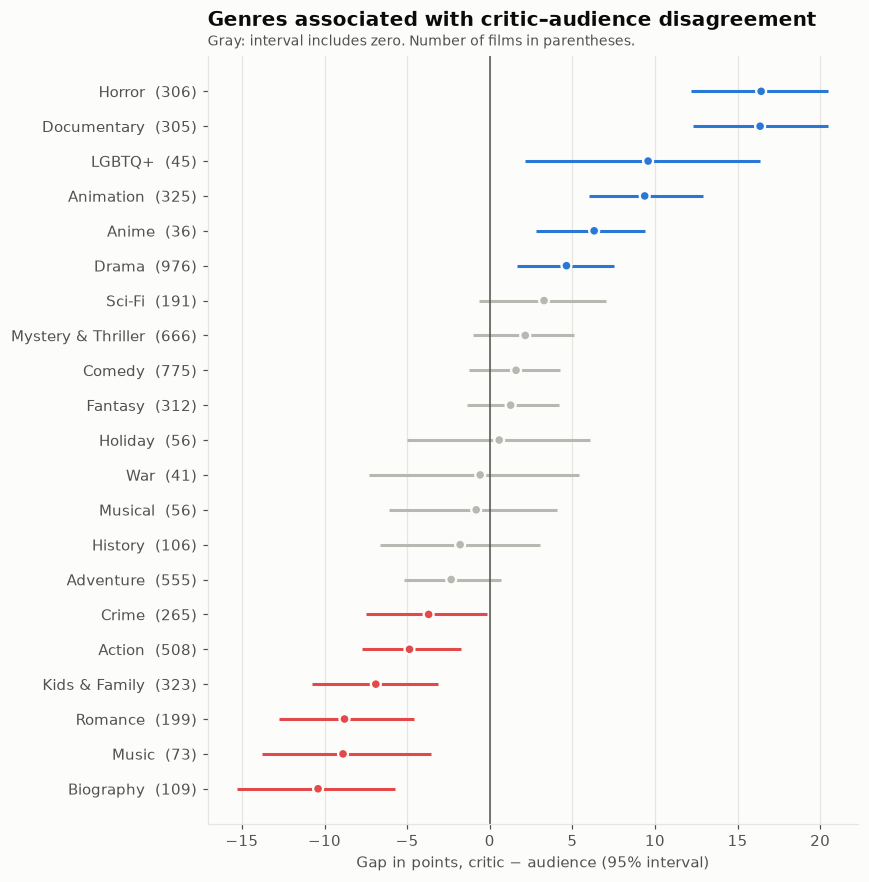

,gap (points),2.5%,97.5%,films,significant
Horror,16.4,12.2,20.5,306,True
Documentary,16.4,12.3,20.5,305,True
LGBTQ+,9.6,2.2,16.3,45,True
Animation,9.4,6.0,12.9,325,True
Anime,6.3,2.8,9.4,36,True
Drama,4.6,1.6,7.5,976,True
Sci-Fi,3.3,-0.6,7.0,191,False
Mystery & Thriller,2.1,-1.0,5.1,666,False
Comedy,1.6,-1.2,4.2,775,False
Fantasy,1.3,-1.4,4.2,312,False


In [19]:
gap = genre_models['Critic − audience gap'].sort_values('coef')
colors = np.where(~gap['significant'], OLD, np.where(gap['coef'] > 0, POS, NEG))
y = np.arange(len(gap))
fig, ax = plt.subplots(figsize=(8, 0.32 * len(gap) + 1.4))
ax.hlines(y, gap['lo'], gap['hi'], color=colors, lw=2)
ax.scatter(gap['coef'], y, color=colors, s=42, zorder=3, edgecolor=SURFACE, linewidth=1.5)
ax.axvline(0, color=INK2, lw=1)
ax.set_yticks(y, [f'{g}  ({n:,})' for g, n in zip(gap.index, gap['titles'])])
ax.grid(axis='y', visible=False)
ax.set_xlabel('Gap in points, critic − audience (95% interval)')
ax.set_title('Genres associated with critic–audience disagreement', pad=20)
ax.text(0, 1.01, 'Gray: interval includes zero. Number of films in parentheses.',
        transform=ax.transAxes, color=INK2, fontsize=9, va='bottom')
plt.tight_layout()
fig.savefig(f'{FIG_DIR}/genre-gap.png', dpi=160, bbox_inches='tight')
plt.show()

display(gap.sort_values('coef', ascending=False)[['coef', 'lo', 'hi', 'titles', 'significant']]
        .round(1).rename(columns={'coef': 'gap (points)', 'lo': '2.5%', 'hi': '97.5%', 'titles': 'films'}))

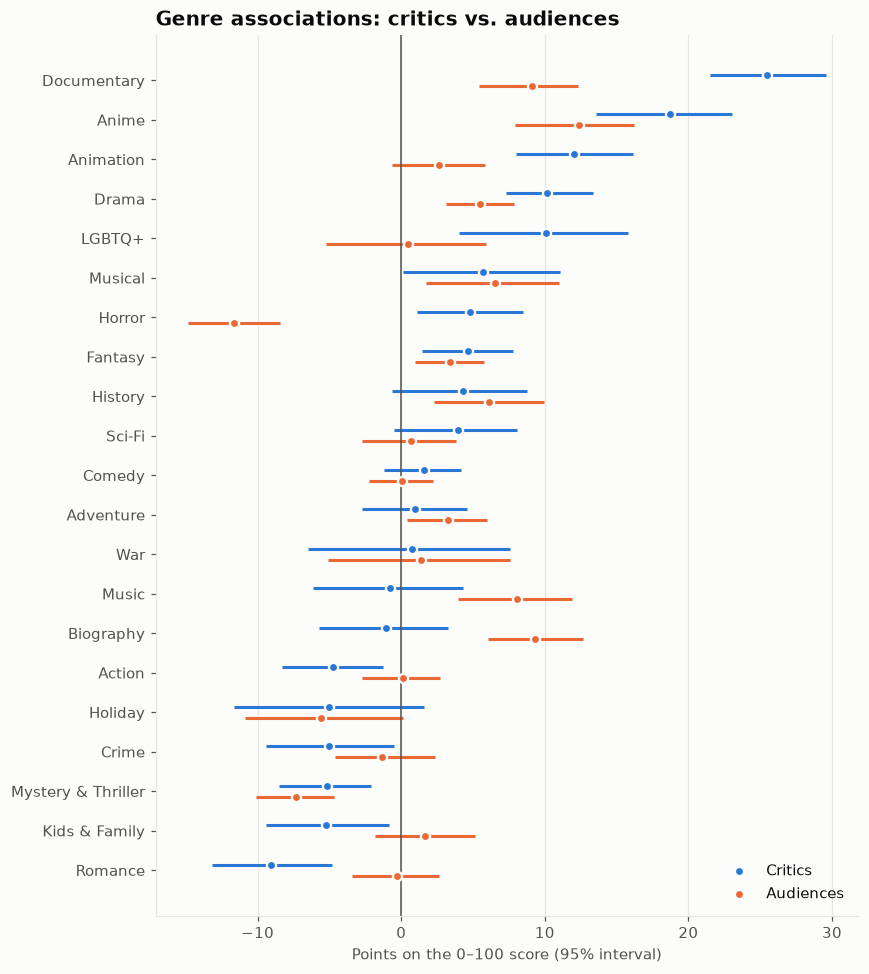

In [20]:
# Critics vs. audiences, genre by genre (same 0-100 scale)
crit, aud = genre_models['RT critics'], genre_models['RT audience']
order = crit['coef'].sort_values().index
y = np.arange(len(order))
fig, ax = plt.subplots(figsize=(8, 0.36 * len(order) + 1.4))
for offset, (name, table, color) in zip([0.14, -0.14], [('Critics', crit, SERIES[0]), ('Audiences', aud, SERIES[1])]):
    t = table.loc[order]
    ax.hlines(y + offset, t['lo'], t['hi'], color=color, lw=2)
    ax.scatter(t['coef'], y + offset, color=color, s=36, zorder=3, edgecolor=SURFACE, linewidth=1.5, label=name)
ax.axvline(0, color=INK2, lw=1)
ax.set_yticks(y, order)
ax.grid(axis='y', visible=False)
ax.set_xlabel('Points on the 0–100 score (95% interval)')
ax.set_title('Genre associations: critics vs. audiences')
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

### 2.2 Book genres

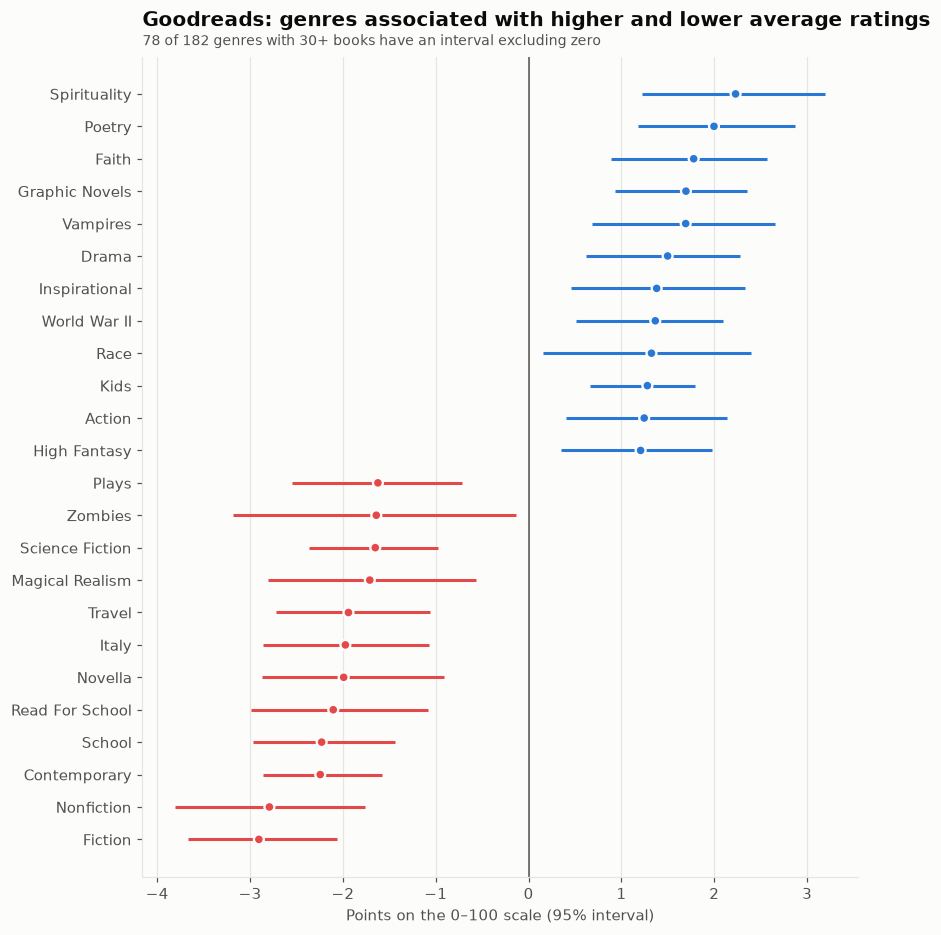

In [21]:
plot_coef_ci(genre_models['Goodreads readers'], 'Goodreads: genres associated with higher and lower average ratings',
             'Points on the 0–100 scale (95% interval)',
             subtitle=f"{genre_models['Goodreads readers']['significant'].sum()} of "
                      f"{len(genre_models['Goodreads readers'])} genres with 30+ books have an interval excluding zero")

### 2.3 Film vs. book genres

Genres that exist on both platforms, matched by name (for example RT *Sci-Fi* ↔ Goodreads *Science Fiction*). The numbers are points on each platform's 0–100 scale; `*` marks an interval that excludes zero.

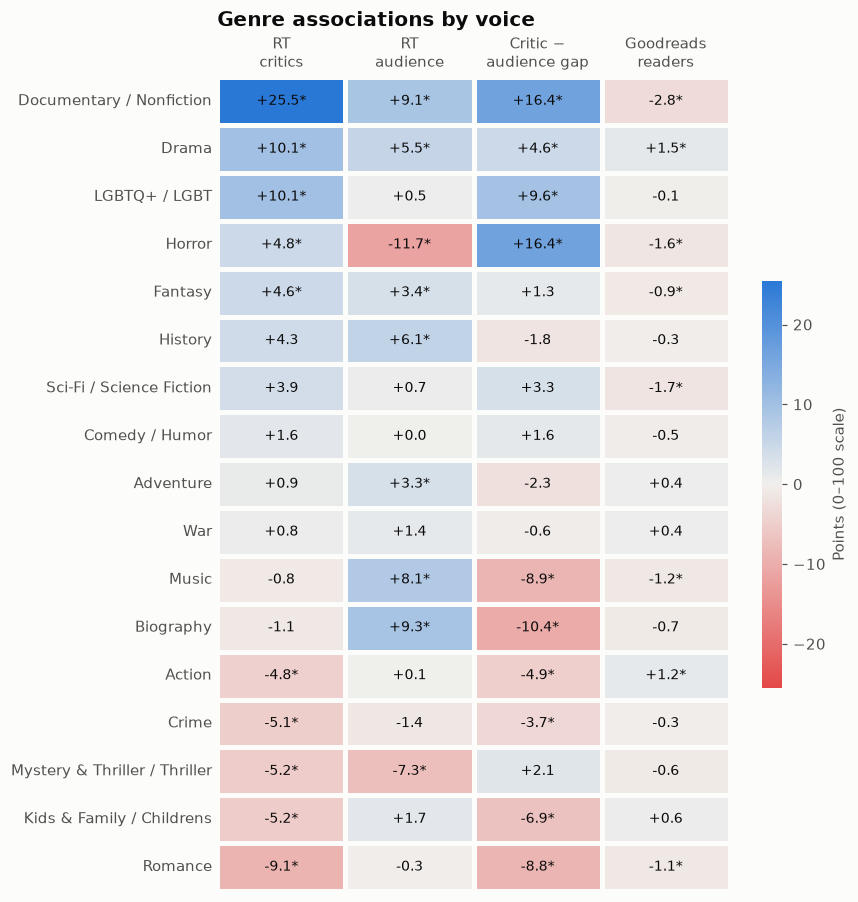

In [22]:
SHARED = {  # RT genre -> Goodreads genre
    'Drama': 'Drama', 'Comedy': 'Humor', 'Mystery & Thriller': 'Thriller', 'Adventure': 'Adventure',
    'Action': 'Action', 'Documentary': 'Nonfiction', 'Fantasy': 'Fantasy', 'Horror': 'Horror',
    'Crime': 'Crime', 'Kids & Family': 'Childrens', 'Romance': 'Romance', 'Sci-Fi': 'Science Fiction',
    'Biography': 'Biography', 'History': 'History', 'Music': 'Music', 'War': 'War', 'LGBTQ+': 'LGBT',
}
voices = {'RT critics': None, 'RT audience': None, 'Critic − audience gap': None, 'Goodreads readers': None}
rows = []
for rt, gr in SHARED.items():
    row = {'genre': rt if rt == gr else f'{rt} / {gr}'}
    for voice in voices:
        key = gr if voice == 'Goodreads readers' else rt
        t = genre_models[voice]
        row[voice] = (t.at[key, 'coef'], t.at[key, 'significant']) if key in t.index else (np.nan, False)
    rows.append(row)
grid = pd.DataFrame(rows).set_index('genre')
values = grid.map(lambda v: v[0])
labels = grid.map(lambda v: '' if pd.isna(v[0]) else f'{v[0]:+.1f}' + ('*' if v[1] else ''))
values = values.loc[values['RT critics'].sort_values(ascending=False).index]
labels = labels.loc[values.index]
short = {'RT critics': 'RT\ncritics', 'RT audience': 'RT\naudience',
         'Critic − audience gap': 'Critic −\naudience gap', 'Goodreads readers': 'Goodreads\nreaders'}
values, labels = values.rename(columns=short), labels.rename(columns=short)

limit = np.nanmax(np.abs(values.to_numpy()))
fig, ax = plt.subplots(figsize=(8, 0.4 * len(values) + 1.5))
ax.set_facecolor(GRID)
sns.heatmap(values, annot=labels, fmt='', cmap=DIVERGING, vmin=-limit, vmax=limit, center=0,
            linewidths=2, linecolor=SURFACE, cbar_kws={'label': 'Points (0–100 scale)', 'shrink': 0.5},
            annot_kws={'fontsize': 9, 'color': INK}, ax=ax)
ax.set_title('Genre associations by voice')
ax.set_xlabel('')
ax.set_ylabel('')
ax.tick_params(axis='x', labeltop=True, labelbottom=False, length=0)
ax.tick_params(axis='y', length=0)
plt.tight_layout()
plt.show()

### 2.4 Comparing model families on genre

The same genre indicators and targets as above, with every model scored by **nested cross-validation**: 5-fold CV repeated twice on the outside, and each model's settings chosen by a 3-fold CV inside each training fold. No fold's test data is ever used to pick settings. Values are mean ± sd R² across the 10 outer folds.

In [23]:
GENRE_REGRESSORS = {   # name: (model, settings grid or None)
    'Mean baseline':           (DummyRegressor(), None),
    'Linear regression (OLS)': (LinearRegression(), None),
    'Ridge':                   (Ridge(), {'alpha': GENRE_ALPHAS}),
    'Lasso':                   (Lasso(max_iter=10000), {'alpha': [0.01, 0.03, 0.1, 0.3, 1]}),
    'Decision tree':           (DecisionTreeRegressor(min_samples_leaf=20, random_state=SEED),
                                {'max_depth': [2, 3, 4, 6]}),
    'Random forest':           (RandomForestRegressor(n_estimators=200, min_samples_leaf=10, n_jobs=-1,
                                                      random_state=SEED), None),
    'Gradient boosting':       (HistGradientBoostingRegressor(max_iter=200, learning_rate=0.05,
                                                              random_state=SEED), None),
}
outer = RepeatedKFold(n_splits=5, n_repeats=2, random_state=SEED)
inner = KFold(n_splits=3, shuffle=True, random_state=SEED)
genre_targets = {**{name: (X_films, y) for name, y in film_targets.items()},
                 'Goodreads readers': (X_books, y_books)}

genre_rows = []
for target, (X, y) in genre_targets.items():
    for name, (model, grid) in GENRE_REGRESSORS.items():
        est = GridSearchCV(model, grid, cv=inner, scoring='r2') if grid else model
        s = cross_val_score(est, X, y, cv=outer, scoring='r2')
        genre_rows.append({'model': name, 'target': target, 'mean': s.mean(), 'sd': s.std()})
genre_cv = pd.DataFrame(genre_rows)
display(genre_cv.assign(r2=lambda d: d['mean'].map('{:.3f}'.format) + ' ± ' + d['sd'].map('{:.3f}'.format))
        .pivot(index='model', columns='target', values='r2').loc[list(GENRE_REGRESSORS), list(genre_targets)])

target,RT critics,RT audience,Critic − audience gap,Goodreads readers
model,,,,
Mean baseline,-0.003 ± 0.004,-0.002 ± 0.002,-0.004 ± 0.003,-0.001 ± 0.001
Linear regression (OLS),0.111 ± 0.038,0.135 ± 0.040,0.081 ± 0.018,0.197 ± 0.016
Ridge,0.112 ± 0.037,0.136 ± 0.039,0.082 ± 0.016,0.214 ± 0.011
Lasso,0.111 ± 0.038,0.137 ± 0.038,0.081 ± 0.016,0.208 ± 0.012
Decision tree,0.092 ± 0.045,0.114 ± 0.036,0.063 ± 0.028,0.143 ± 0.027
Random forest,0.116 ± 0.043,0.124 ± 0.039,0.078 ± 0.022,0.232 ± 0.019
Gradient boosting,0.108 ± 0.051,0.123 ± 0.047,0.072 ± 0.022,0.262 ± 0.019


### 2.5 Which films split critics and audiences? A classification view

Each film gets one of three labels from its gap: **critics 20+ points higher**, **audiences 20+ points higher**, or **within 20 points**. The models predict the label from genre alone, scored by nested CV (5-fold stratified, repeated twice). Macro-F1 averages F1 across the three labels, so a model can't score well by always predicting the most common one.

In [24]:
gap_points = films['tomatometer'] - films['audience_score']
split_label = pd.Series(np.select([gap_points >= 20, gap_points <= -20],
                                  ['Critics 20+ higher', 'Audiences 20+ higher'], 'Within 20 points'),
                        index=films.index)
print(split_label.value_counts().to_dict())

SPLIT_MODELS = {
    'Majority class':      (DummyClassifier(strategy='most_frequent'), None),
    'Logistic regression': (LogisticRegression(max_iter=3000), {'C': [0.1, 1, 10]}),
    'Decision tree':       (DecisionTreeClassifier(min_samples_leaf=20, random_state=SEED),
                            {'max_depth': [2, 3, 4, 6]}),
    'Random forest':       (RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1,
                                                   random_state=SEED), None),
    'Gradient boosting':   (HistGradientBoostingClassifier(max_iter=200, learning_rate=0.05, random_state=SEED), None),
}
outer_c = RepeatedStratifiedKFold(n_splits=5, n_repeats=2, random_state=SEED)
inner_c = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
split_rows = []
for name, (model, grid) in SPLIT_MODELS.items():
    est = GridSearchCV(model, grid, cv=inner_c, scoring='f1_macro') if grid else model
    s = cross_validate(est, X_films, split_label, cv=outer_c, scoring=['f1_macro', 'accuracy', 'balanced_accuracy'])
    split_rows.append({'model': name,
                       **{m: f"{s[f'test_{m}'].mean():.3f} ± {s[f'test_{m}'].std():.3f}"
                          for m in ['f1_macro', 'balanced_accuracy', 'accuracy']}})
display(pd.DataFrame(split_rows).set_index('model')
        .rename(columns={'f1_macro': 'macro-F1', 'balanced_accuracy': 'balanced accuracy'}))

{'Within 20 points': 1312, 'Critics 20+ higher': 595, 'Audiences 20+ higher': 546}


,macro-F1,balanced accuracy,accuracy
model,,,
Majority class,0.232 ± 0.000,0.333 ± 0.000,0.535 ± 0.001
Logistic regression,0.370 ± 0.019,0.395 ± 0.014,0.545 ± 0.017
Decision tree,0.340 ± 0.020,0.386 ± 0.017,0.549 ± 0.014
Random forest,0.365 ± 0.026,0.397 ± 0.016,0.556 ± 0.015
Gradient boosting,0.439 ± 0.024,0.436 ± 0.021,0.549 ± 0.024


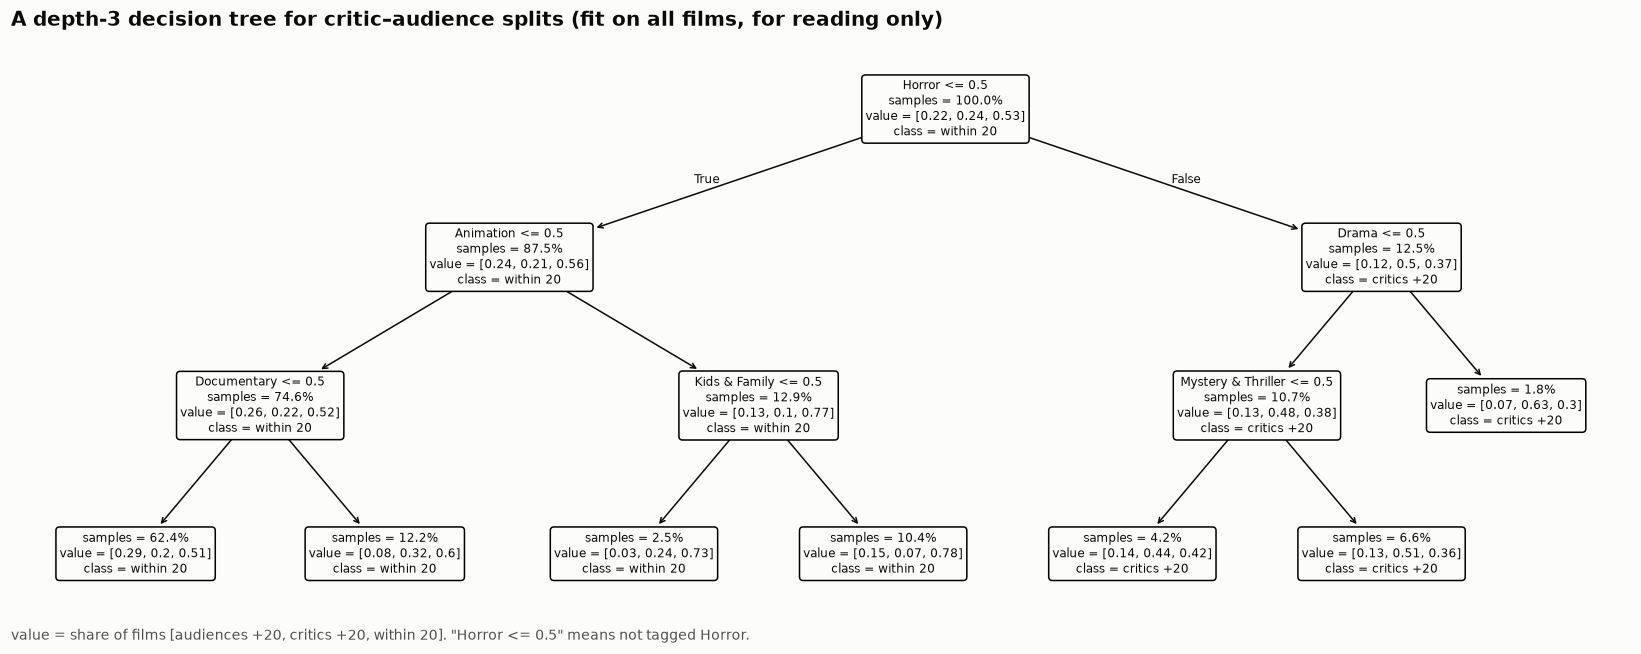

In [25]:
split_tree = DecisionTreeClassifier(max_depth=3, min_samples_leaf=40, random_state=SEED).fit(X_films, split_label)
short_names = {'Audiences 20+ higher': 'audiences +20', 'Critics 20+ higher': 'critics +20',
               'Within 20 points': 'within 20'}
fig, ax = plt.subplots(figsize=(19, 7))
plot_tree(split_tree, feature_names=list(X_films.columns),
          class_names=[short_names[c] for c in split_tree.classes_],
          filled=False, impurity=False, proportion=True, rounded=True, precision=2, fontsize=8, ax=ax)
ax.set_title('A depth-3 decision tree for critic–audience splits (fit on all films, for reading only)')
ax.text(0, -0.02, 'value = share of films [audiences +20, critics +20, within 20]. "Horror <= 0.5" means not tagged Horror.',
        transform=ax.transAxes, color=INK2, fontsize=9)
plt.show()

**Model choice barely matters for film genres, and boosting helps for books.**

| Nested-CV R² | RT critics | RT audience | Critic − audience gap | Goodreads readers |
|---|---|---|---|---|
| Ridge | 0.112 | 0.136 | **0.082** | 0.214 |
| Lasso | 0.111 | **0.137** | 0.081 | 0.208 |
| Linear regression (OLS) | 0.111 | 0.135 | 0.081 | 0.197 |
| Random forest | **0.116** | 0.124 | 0.078 | 0.232 |
| Gradient boosting | 0.108 | 0.123 | 0.072 | **0.262** |
| Decision tree | 0.092 | 0.114 | 0.063 | 0.143 |

- **Films:** with 21 genre flags, every linear model lands within 0.005 of the others, and tree ensembles add nothing. Genre effects on film scores are close to additive.
- **Books:** gradient boosting (0.26) and the random forest (0.23) beat Ridge (0.21). With 182 overlapping reader tags, combinations of tags seem to carry information that an additive model misses, and tree ensembles can capture those interactions. Which combinations matter is left for RQ3.

**Predicting which films split critics and audiences** (54% within 20 points, 24% critics 20+ higher, 22% audiences 20+ higher):

| Nested CV | macro-F1 | balanced accuracy | accuracy |
|---|---|---|---|
| Majority class | 0.23 | 0.33 | 0.54 |
| Logistic regression | 0.37 | 0.40 | 0.55 |
| Decision tree | 0.34 | 0.39 | 0.55 |
| Random forest | 0.37 | 0.40 | 0.56 |
| **Gradient boosting** | **0.44** | **0.44** | 0.55 |

- **Genre alone gives a weak but real signal.** Gradient boosting nearly doubles the majority baseline's macro-F1, but accuracy barely moves, since most films are "within 20" for every model. Content rating, runtime and review text (proposed RQ2) are needed for a useful classifier.
- **The readable tree tells the same story as the gap chart.** Its first question is *Horror?* Half of horror films have critics 20+ points higher (vs. 24% overall), rising to 63% for horror dramas. Animation is where critics and audiences agree most: 77% of non-horror animated films fall within 20 points.

## Conclusion: Research Question 2

**Genre explains little of a title's score, but it clearly marks where critics and audiences disagree.** On held-out folds, genre alone explains 11% of Tomatometer variance, 14% of audience score, 8% of the critic–audience gap, and 21% of Goodreads averages (where the averages themselves barely vary: sd 0.3 stars).

| Model | Titles | Genres | CV R² (mean ± sd) | Genres with interval excluding 0 |
|---|---|---|---|---|
| RT critics | 2,453 | 21 | 0.11 ± 0.03 | 13 |
| RT audience | 2,453 | 21 | 0.14 ± 0.04 | 11 |
| Critic − audience gap | 2,453 | 21 | 0.08 ± 0.02 | 12 |
| Goodreads readers | 4,023 | 182 | 0.21 ± 0.01 | 78 |

### Where critics and audiences split (points on a 0–100 scale)
- **Critics score higher than audiences:** Horror (+16.4) and Documentary (+16.4) by the widest margins, then LGBTQ+ (+9.6), Animation (+9.4), Anime and Drama.
- **Audiences score higher than critics:** Biography (−10.4), Music (−8.9), Romance (−8.8), Kids & Family (−6.9), Action (−4.9) and Crime (−3.7).
- **Horror is the clearest split.** Audiences rate horror 11.7 points below other films; critics rate it 4.8 points *above*. The class version reported horror as negative "for film", which is true only for audiences.
- **Documentaries are rewarded by both voices,** but far more by critics (+25.5 vs. +9.1).
- **Biographies and music films are audience favorites** (+9.3 and +8.1) that critics treat as average.

### Books
- Genre effects on Goodreads are small: about ±3 points on the 0–100 scale, or ±0.12 stars. Average ratings are compressed, so even real differences are tiny.
- Higher: Spirituality, Poetry, Faith, Graphic Novels, Vampires, Drama. Lower: the broad Fiction and Nonfiction tags (90% of tagged books carry one, so books without either are a small, niche group), Contemporary, School and **Read For School**. Assigned reading is rated lower.
- **Film and book genres don't line up.** Documentary films are critic darlings (+25.5) while nonfiction books rate slightly lower (−2.8). Horror is mildly negative for books (−1.6) and strongly negative only for film audiences.

### What changed from the class version
- **Letterboxd is gone.** Its "genre explains half the variance" result came from comparing a top-500 list with a bottom-500 list.
- **Variety and Reality** (the class version's biggest critic genres) had one film each, and **Gaming** and **Social Media** (its top book genres) three books and one book. With a 30-title minimum and intervals, none of them appear.
- **Films with missing scores are dropped** instead of set to the median, which had pulled every genre toward zero.
- **The gap is modeled directly** instead of comparing two separate regressions by eye.

Genre is a weak predictor and a useful descriptor, which is why the next section replaces this question with two sharper ones.

# Follow-up questions

Question 2 shows that genre explains only a small share of ratings, and that critic–audience disagreement is the more interesting signal. Two sharper questions replace it, each in its own notebook.

### Where do critics and audiences disagree, and can we predict it? (`gap-analysis.ipynb`)

Which film attributes go with the critic-minus-audience score gap, and can a model flag, before release, films that will split critics and audiences by 20+ points? Uses only features known before any review, with nested cross-validation and a check of how much of the gap is sampling noise.

**Answer in brief:** critics favor unrated, short, non-English, horror and documentary films; audiences favor PG-13, longer, Hindi-language and widely seen films. Pre-release features explain 17% of the gap (double genre alone), and the model's most confident 10% of "split" calls are right 78% of the time, against a 47% base rate.

### What makes a book divisive? (`divisive-books.ipynb`)

Holding a book's average rating fixed, which books split readers instead of converging on a consensus? Uses the spread of each book's 1–5 star ratings, with the average as a control and cross-validation grouped by author.

**Answer in brief:** subject matter that invites moral judgment (erotic and dark romance, religious books, books about abuse) is the most divisive; mysteries and crime fiction the least. Metadata known at publication explains about a third of the divisiveness the average rating doesn't.

# Limitations

- **The sample isn't random.** Goodreads books come from popular Listopia lists and RT films from browse pages, so obscure titles are under-represented and average ratings skew high (Goodreads books average 4.1 stars).
- **Reviews per title are thin on RT.** The median film has about 10 critic and 6 audience reviews in this data, far fewer than RT shows. Review-level results for RT rest on a small slice per film.
- **Language.** Models use English reviews only. The language detector mislabels some very short or mixed-language reviews, but most of those fall under the 5-word minimum anyway.
- **The title-average baseline leaks a little.** A title's published average includes the review being predicted. With dozens to thousands of ratings per title the effect is small, but it makes that baseline slightly optimistic.
- **TF-IDF ignores word order.** "Not good" and "good" share the word *good*; two-word phrases help only partly. Phase 3 compares sentence embeddings.
- **Associations, not effects.** Genre and word coefficients describe which titles and reviews tend to score higher. They don't show that adding a genre or a word would change a rating.
- **One snapshot.** Scores were scraped in spring 2026. Tomatometer and audience scores drift as reviews accumulate, especially for the 2025–2026 releases that make up a large share of the films.